# Proyek Akhir: Menyelesaikan Permasalahan Human Resource

- Nama: M. Ardifa Rizqi Ramadhan
- Email: ardifasgt17@gmail.com
- Id Dicoding: ardifarr

## Persiapan

### Menyiapkan library yang dibutuhkan

In [176]:
# Import Library
import math
import pandas as pd
pd.set_option('display.max_rows', 50)
pd.set_option('display.max_columns', 50)
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import math

from scipy.stats import pointbiserialr, chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from imblearn.over_sampling import SMOTE

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (classification_report, roc_auc_score,
                             f1_score,confusion_matrix, ConfusionMatrixDisplay)

from sklearn.inspection import permutation_importance
import joblib

### Menyiapkan data yang akan digunakan

In [177]:
# Load Data
employees_df = pd.read_csv("https://raw.githubusercontent.com/dicodingacademy/dicoding_dataset/main/employee/employee_data.csv",encoding='windows-1252')
employees_df.head()

,EmployeeId,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,1,38,NaN,Travel_Frequently,1444,Human Resources,1,4,Other,1,4,Male,88,3,1,Human Resources,2,Married,2991,5224,0,Y,Yes,11,3,2,80,1,7,2,3,6,2,1,2
1,2,37,1.0,Travel_Rarely,1141,Research & Development,11,2,Medical,1,1,Female,61,1,2,Healthcare Representative,2,Married,4777,14382,5,Y,No,15,3,1,80,0,15,2,1,1,0,0,0
2,3,51,1.0,Travel_Rarely,1323,Research & Development,4,4,Life Sciences,1,1,Male,34,3,1,Research Scientist,3,Married,2461,10332,9,Y,Yes,12,3,3,80,3,18,2,4,10,0,2,7
3,4,42,0.0,Travel_Frequently,555,Sales,26,3,Marketing,1,3,Female,77,3,4,Sales Executive,2,Married,13525,14864,5,Y,No,14,3,4,80,1,23,2,4,20,4,4,8
4,5,40,NaN,Travel_Rarely,1194,Research & Development,2,4,Medical,1,3,Female,98,3,1,Research Scientist,3,Married,2001,12549,2,Y,No,14,3,2,80,3,20,2,3,5,3,0,2


## Data Understanding

In [178]:
employees_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 35 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   EmployeeId                1470 non-null   int64  
 1   Age                       1470 non-null   int64  
 2   Attrition                 1058 non-null   float64
 3   BusinessTravel            1470 non-null   object 
 4   DailyRate                 1470 non-null   int64  
 5   Department                1470 non-null   object 
 6   DistanceFromHome          1470 non-null   int64  
 7   Education                 1470 non-null   int64  
 8   EducationField            1470 non-null   object 
 9   EmployeeCount             1470 non-null   int64  
 10  EnvironmentSatisfaction   1470 non-null   int64  
 11  Gender                    1470 non-null   object 
 12  HourlyRate                1470 non-null   int64  
 13  JobInvolvement            1470 non-null   int64  
 14  JobLevel

In [179]:
employees_df.describe()

,EmployeeId,Age,Attrition,DailyRate,DistanceFromHome,Education,EmployeeCount,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,JobSatisfaction,MonthlyIncome,MonthlyRate,NumCompaniesWorked,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1470.000000,1470.000000,1058.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.0,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000,1470.000000
mean,735.500000,36.923810,0.169187,802.485714,9.192517,2.912925,1.0,2.721769,65.891156,2.729932,2.063946,2.728571,6502.931293,14313.103401,2.693197,15.209524,3.153741,2.712245,80.0,0.793878,11.279592,2.799320,2.761224,7.008163,4.229252,2.187755,4.123129
std,424.496761,9.135373,0.375094,403.509100,8.106864,1.024165,0.0,1.093082,20.329428,0.711561,1.106940,1.102846,4707.956783,7117.786044,2.498009,3.659938,0.360824,1.081209,0.0,0.852077,7.780782,1.289271,0.706476,6.126525,3.623137,3.222430,3.568136
min,1.000000,18.000000,0.000000,102.000000,1.000000,1.000000,1.0,1.000000,30.000000,1.000000,1.000000,1.000000,1009.000000,2094.000000,0.000000,11.000000,3.000000,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,368.250000,30.000000,0.000000,465.000000,2.000000,2.000000,1.0,2.000000,48.000000,2.000000,1.000000,2.000000,2911.000000,8047.000000,1.000000,12.000000,3.000000,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,735.500000,36.000000,0.000000,802.000000,7.000000,3.000000,1.0,3.000000,66.000000,3.000000,2.000000,3.000000,4919.000000,14235.500000,2.000000,14.000000,3.000000,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,1102.750000,43.000000,0.000000,1157.000000,14.000000,4.000000,1.0,4.000000,83.750000,3.000000,3.000000,4.000000,8379.000000,20461.500000,4.000000,18.000000,3.000000,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,1470.000000,60.000000,1.000000,1499.000000,29.000000,5.000000,1.0,4.000000,100.000000,4.000000,5.000000,4.000000,19999.000000,26999.000000,9.000000,25.000000,4.000000,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


In [180]:
employees_df.duplicated().sum()

np.int64(0)

In [181]:
employees_df.isna().sum()

,0
EmployeeId,0
Age,0
Attrition,412
BusinessTravel,0
DailyRate,0
Department,0
DistanceFromHome,0
Education,0
EducationField,0
EmployeeCount,0


In [182]:
employees_df[employees_df['Attrition'].isna()]

,EmployeeId,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,1,38,NaN,Travel_Frequently,1444,Human Resources,1,4,Other,1,4,Male,88,3,1,Human Resources,2,Married,2991,5224,0,Y,Yes,11,3,2,80,1,7,2,3,6,2,1,2
4,5,40,NaN,Travel_Rarely,1194,Research & Development,2,4,Medical,1,3,Female,98,3,1,Research Scientist,3,Married,2001,12549,2,Y,No,14,3,2,80,3,20,2,3,5,3,0,2
5,6,29,NaN,Travel_Rarely,352,Human Resources,6,1,Medical,1,4,Male,87,2,1,Human Resources,2,Married,2804,15434,1,Y,No,11,3,4,80,0,1,3,3,1,0,0,0
12,13,47,NaN,Travel_Rarely,571,Sales,14,3,Medical,1,3,Female,78,3,2,Sales Executive,3,Married,4591,24200,3,Y,Yes,17,3,3,80,1,11,4,2,5,4,1,2
18,19,25,NaN,Travel_Frequently,772,Research & Development,2,1,Life Sciences,1,4,Male,77,4,2,Manufacturing Director,3,Divorced,5206,4973,1,Y,No,17,3,3,80,2,7,6,3,7,7,0,7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1443,1444,24,NaN,Travel_Frequently,567,Research & Development,2,1,Technical Degree,1,1,Female,32,3,1,Research Scientist,4,Single,3760,17218,1,Y,Yes,13,3,3,80,0,6,2,3,6,3,1,3
1447,1448,42,NaN,Travel_Frequently,288,Research & Development,2,3,Life Sciences,1,4,Male,40,3,3,Healthcare Representative,4,Married,10124,18611,2,Y,Yes,14,3,3,80,1,24,3,1,20,8,13,9
1448,1449,38,NaN,Travel_Rarely,437,Sales,16,3,Life Sciences,1,2,Female,90,3,2,Sales Executive,2,Single,4198,16379,2,Y,No,12,3,2,80,0,8,5,4,3,2,1,2
1462,1463,41,NaN,Travel_Rarely,1206,Sales,23,2,Life Sciences,1,4,Male,80,3,3,Sales Executive,3,Single,7082,11591,3,Y,Yes,16,3,4,80,0,21,2,3,2,0,0,2


In [183]:
employees_df[['EmployeeCount', 'Over18', 'StandardHours']].nunique()

,0
EmployeeCount,1
Over18,1
StandardHours,1


In [184]:
employees_df.describe(include='object')

,BusinessTravel,Department,EducationField,Gender,JobRole,MaritalStatus,Over18,OverTime
count,1470,1470,1470,1470,1470,1470,1470,1470
unique,3,3,6,2,9,3,1,2
top,Travel_Rarely,Research & Development,Life Sciences,Male,Sales Executive,Married,Y,No
freq,1043,961,606,882,326,673,1470,1054


In [185]:
categorical_cols = employees_df.select_dtypes(include=['object']).columns
print("Analisis Fitur Kategorikal:")

for col in categorical_cols:
    print(f"Unique Values: {employees_df[col].unique()}")
    print(f"Value Counts:\n{employees_df[col].value_counts()}\n")

Analisis Fitur Kategorikal:
Unique Values: ['Travel_Frequently' 'Travel_Rarely' 'Non-Travel']
Value Counts:
BusinessTravel
Travel_Rarely        1043
Travel_Frequently     277
Non-Travel            150
Name: count, dtype: int64

Unique Values: ['Human Resources' 'Research & Development' 'Sales']
Value Counts:
Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64

Unique Values: ['Other' 'Medical' 'Life Sciences' 'Marketing' 'Technical Degree'
 'Human Resources']
Value Counts:
EducationField
Life Sciences       606
Medical             464
Marketing           159
Technical Degree    132
Other                82
Human Resources      27
Name: count, dtype: int64

Unique Values: ['Male' 'Female']
Value Counts:
Gender
Male      882
Female    588
Name: count, dtype: int64

Unique Values: ['Human Resources' 'Healthcare Representative' 'Research Scientist'
 'Sales Executive' 'Manager' 'Laboratory Technician' 'Research Direct

Temuan dari Data Understanding

* Terdapat 412 nilai NaN pada kolom Attrition
* Terdapat 3 kolom yang yang tidak informatif yaitu `EmployeeCount`, `Over18`, `StandardHours`

## Data Preparation / Preprocessing

### Data Cleaning

In [186]:
clean_df = employees_df.copy()
clean_df.head()

,EmployeeId,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,1,38,NaN,Travel_Frequently,1444,Human Resources,1,4,Other,1,4,Male,88,3,1,Human Resources,2,Married,2991,5224,0,Y,Yes,11,3,2,80,1,7,2,3,6,2,1,2
1,2,37,1.0,Travel_Rarely,1141,Research & Development,11,2,Medical,1,1,Female,61,1,2,Healthcare Representative,2,Married,4777,14382,5,Y,No,15,3,1,80,0,15,2,1,1,0,0,0
2,3,51,1.0,Travel_Rarely,1323,Research & Development,4,4,Life Sciences,1,1,Male,34,3,1,Research Scientist,3,Married,2461,10332,9,Y,Yes,12,3,3,80,3,18,2,4,10,0,2,7
3,4,42,0.0,Travel_Frequently,555,Sales,26,3,Marketing,1,3,Female,77,3,4,Sales Executive,2,Married,13525,14864,5,Y,No,14,3,4,80,1,23,2,4,20,4,4,8
4,5,40,NaN,Travel_Rarely,1194,Research & Development,2,4,Medical,1,3,Female,98,3,1,Research Scientist,3,Married,2001,12549,2,Y,No,14,3,2,80,3,20,2,3,5,3,0,2


#### Drop missed cols

In [187]:
drop_cols = ['EmployeeCount', 'StandardHours', 'Over18']
clean_df = clean_df.drop(drop_cols, axis=1)

In [188]:
clean_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1470 entries, 0 to 1469
Data columns (total 32 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   EmployeeId                1470 non-null   int64  
 1   Age                       1470 non-null   int64  
 2   Attrition                 1058 non-null   float64
 3   BusinessTravel            1470 non-null   object 
 4   DailyRate                 1470 non-null   int64  
 5   Department                1470 non-null   object 
 6   DistanceFromHome          1470 non-null   int64  
 7   Education                 1470 non-null   int64  
 8   EducationField            1470 non-null   object 
 9   EnvironmentSatisfaction   1470 non-null   int64  
 10  Gender                    1470 non-null   object 
 11  HourlyRate                1470 non-null   int64  
 12  JobInvolvement            1470 non-null   int64  
 13  JobLevel                  1470 non-null   int64  
 14  JobRole 

#### Drop Value NaN

In [189]:
clean_df.dropna(subset=['Attrition'], inplace=True)
clean_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1058 entries, 1 to 1469
Data columns (total 32 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   EmployeeId                1058 non-null   int64  
 1   Age                       1058 non-null   int64  
 2   Attrition                 1058 non-null   float64
 3   BusinessTravel            1058 non-null   object 
 4   DailyRate                 1058 non-null   int64  
 5   Department                1058 non-null   object 
 6   DistanceFromHome          1058 non-null   int64  
 7   Education                 1058 non-null   int64  
 8   EducationField            1058 non-null   object 
 9   EnvironmentSatisfaction   1058 non-null   int64  
 10  Gender                    1058 non-null   object 
 11  HourlyRate                1058 non-null   int64  
 12  JobInvolvement            1058 non-null   int64  
 13  JobLevel                  1058 non-null   int64  
 14  JobRole      

In [190]:
model_df = clean_df.copy()

clean_df.to_csv('cleaned_employee_data.csv', index=False)

In [191]:
attrition_mapping = {0: 'No', 1: 'Yes'}
clean_df['Attrition'] = clean_df['Attrition'].map(attrition_mapping)

education_mapping = {1: 'Bellow College', 2: 'College', 3: 'Bachelor', 4: 'Master', 5: 'Doctor'}
clean_df['Education'] = clean_df['Education'].map(education_mapping)

satisfaction_employee_mapping = {1: 'Low', 2: 'Medium', 3: 'High', 4: 'Very High'}
clean_df['EnvironmentSatisfaction'] = clean_df['EnvironmentSatisfaction'].map(satisfaction_employee_mapping)
clean_df['JobInvolvement'] = clean_df['JobInvolvement'].map(satisfaction_employee_mapping)
clean_df['JobSatisfaction'] = clean_df['JobSatisfaction'].map(satisfaction_employee_mapping)
clean_df['RelationshipSatisfaction'] = clean_df['RelationshipSatisfaction'].map(satisfaction_employee_mapping)

performance_mapping = {1: 'Low', 2: 'Good', 3: 'Excellent', 4: 'Outstanding'}
clean_df['PerformanceRating'] = clean_df['PerformanceRating'].map(performance_mapping)
clean_df['WorkLifeBalance'] = clean_df['WorkLifeBalance'].map(performance_mapping)

clean_df.head()

,EmployeeId,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
1,2,37,Yes,Travel_Rarely,1141,Research & Development,11,College,Medical,Low,Female,61,Low,2,Healthcare Representative,Medium,Married,4777,14382,5,No,15,Excellent,Low,0,15,2,Low,1,0,0,0
2,3,51,Yes,Travel_Rarely,1323,Research & Development,4,Master,Life Sciences,Low,Male,34,High,1,Research Scientist,High,Married,2461,10332,9,Yes,12,Excellent,High,3,18,2,Outstanding,10,0,2,7
3,4,42,No,Travel_Frequently,555,Sales,26,Bachelor,Marketing,High,Female,77,High,4,Sales Executive,Medium,Married,13525,14864,5,No,14,Excellent,Very High,1,23,2,Outstanding,20,4,4,8
6,7,40,No,Travel_Rarely,1124,Sales,1,College,Medical,Medium,Male,57,Low,2,Sales Executive,Very High,Married,7457,13273,2,Yes,22,Outstanding,High,3,6,2,Good,4,3,0,2
7,8,55,Yes,Travel_Rarely,725,Research & Development,2,Bachelor,Medical,Very High,Male,78,High,5,Manager,Low,Married,19859,21199,5,Yes,13,Excellent,Very High,1,24,2,Excellent,5,2,1,4


### Exploratory Data Analysis (EDA)


#### Explore kolom target (`Attrition`)

In [192]:
clean_df['Attrition'].value_counts()

,count
Attrition,
No,879
Yes,179


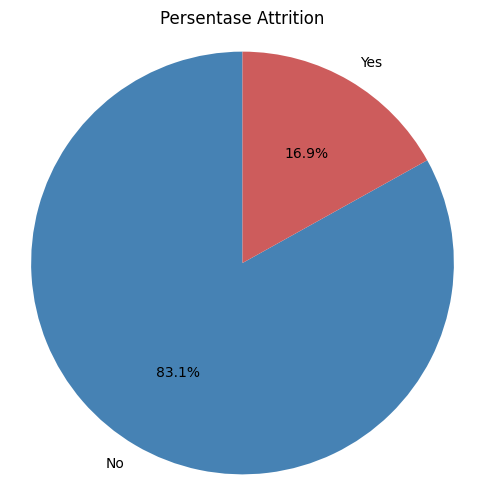

In [193]:
#grafik persentase attrition
attrition_counts = clean_df['Attrition'].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(attrition_counts, labels=attrition_counts.index, autopct='%1.1f%%', startangle=90, colors=['steelblue', 'indianred'])
plt.title('Persentase Attrition')
plt.axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

**Temuan**
* karyawan yang keluar berjumlah sekitar 16,9% atau sebanyak 179 karyawan.
* sedangkan karyawan yang bertahan sekitar 83,1% atau sebanyak 879 karyawan.

**Insight**
* Angka 16,9% ini cukup signifikan, menunjukkan bahwa ada potensi masalah retensi karyawan yang perlu menjadi perhatian serius bagi tim HR guna menganalisis faktor-faktor penyebab dan merancang strategi pencegahan.


In [194]:
numerical_cols = clean_df.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_cols = clean_df.select_dtypes(include=['object']).columns.tolist()

print(numerical_cols)
print(categorical_cols)

['EmployeeId', 'Age', 'DailyRate', 'DistanceFromHome', 'HourlyRate', 'JobLevel', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']
['Attrition', 'BusinessTravel', 'Department', 'Education', 'EducationField', 'EnvironmentSatisfaction', 'Gender', 'JobInvolvement', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'OverTime', 'PerformanceRating', 'RelationshipSatisfaction', 'WorkLifeBalance']


#### Distribusi Numerical

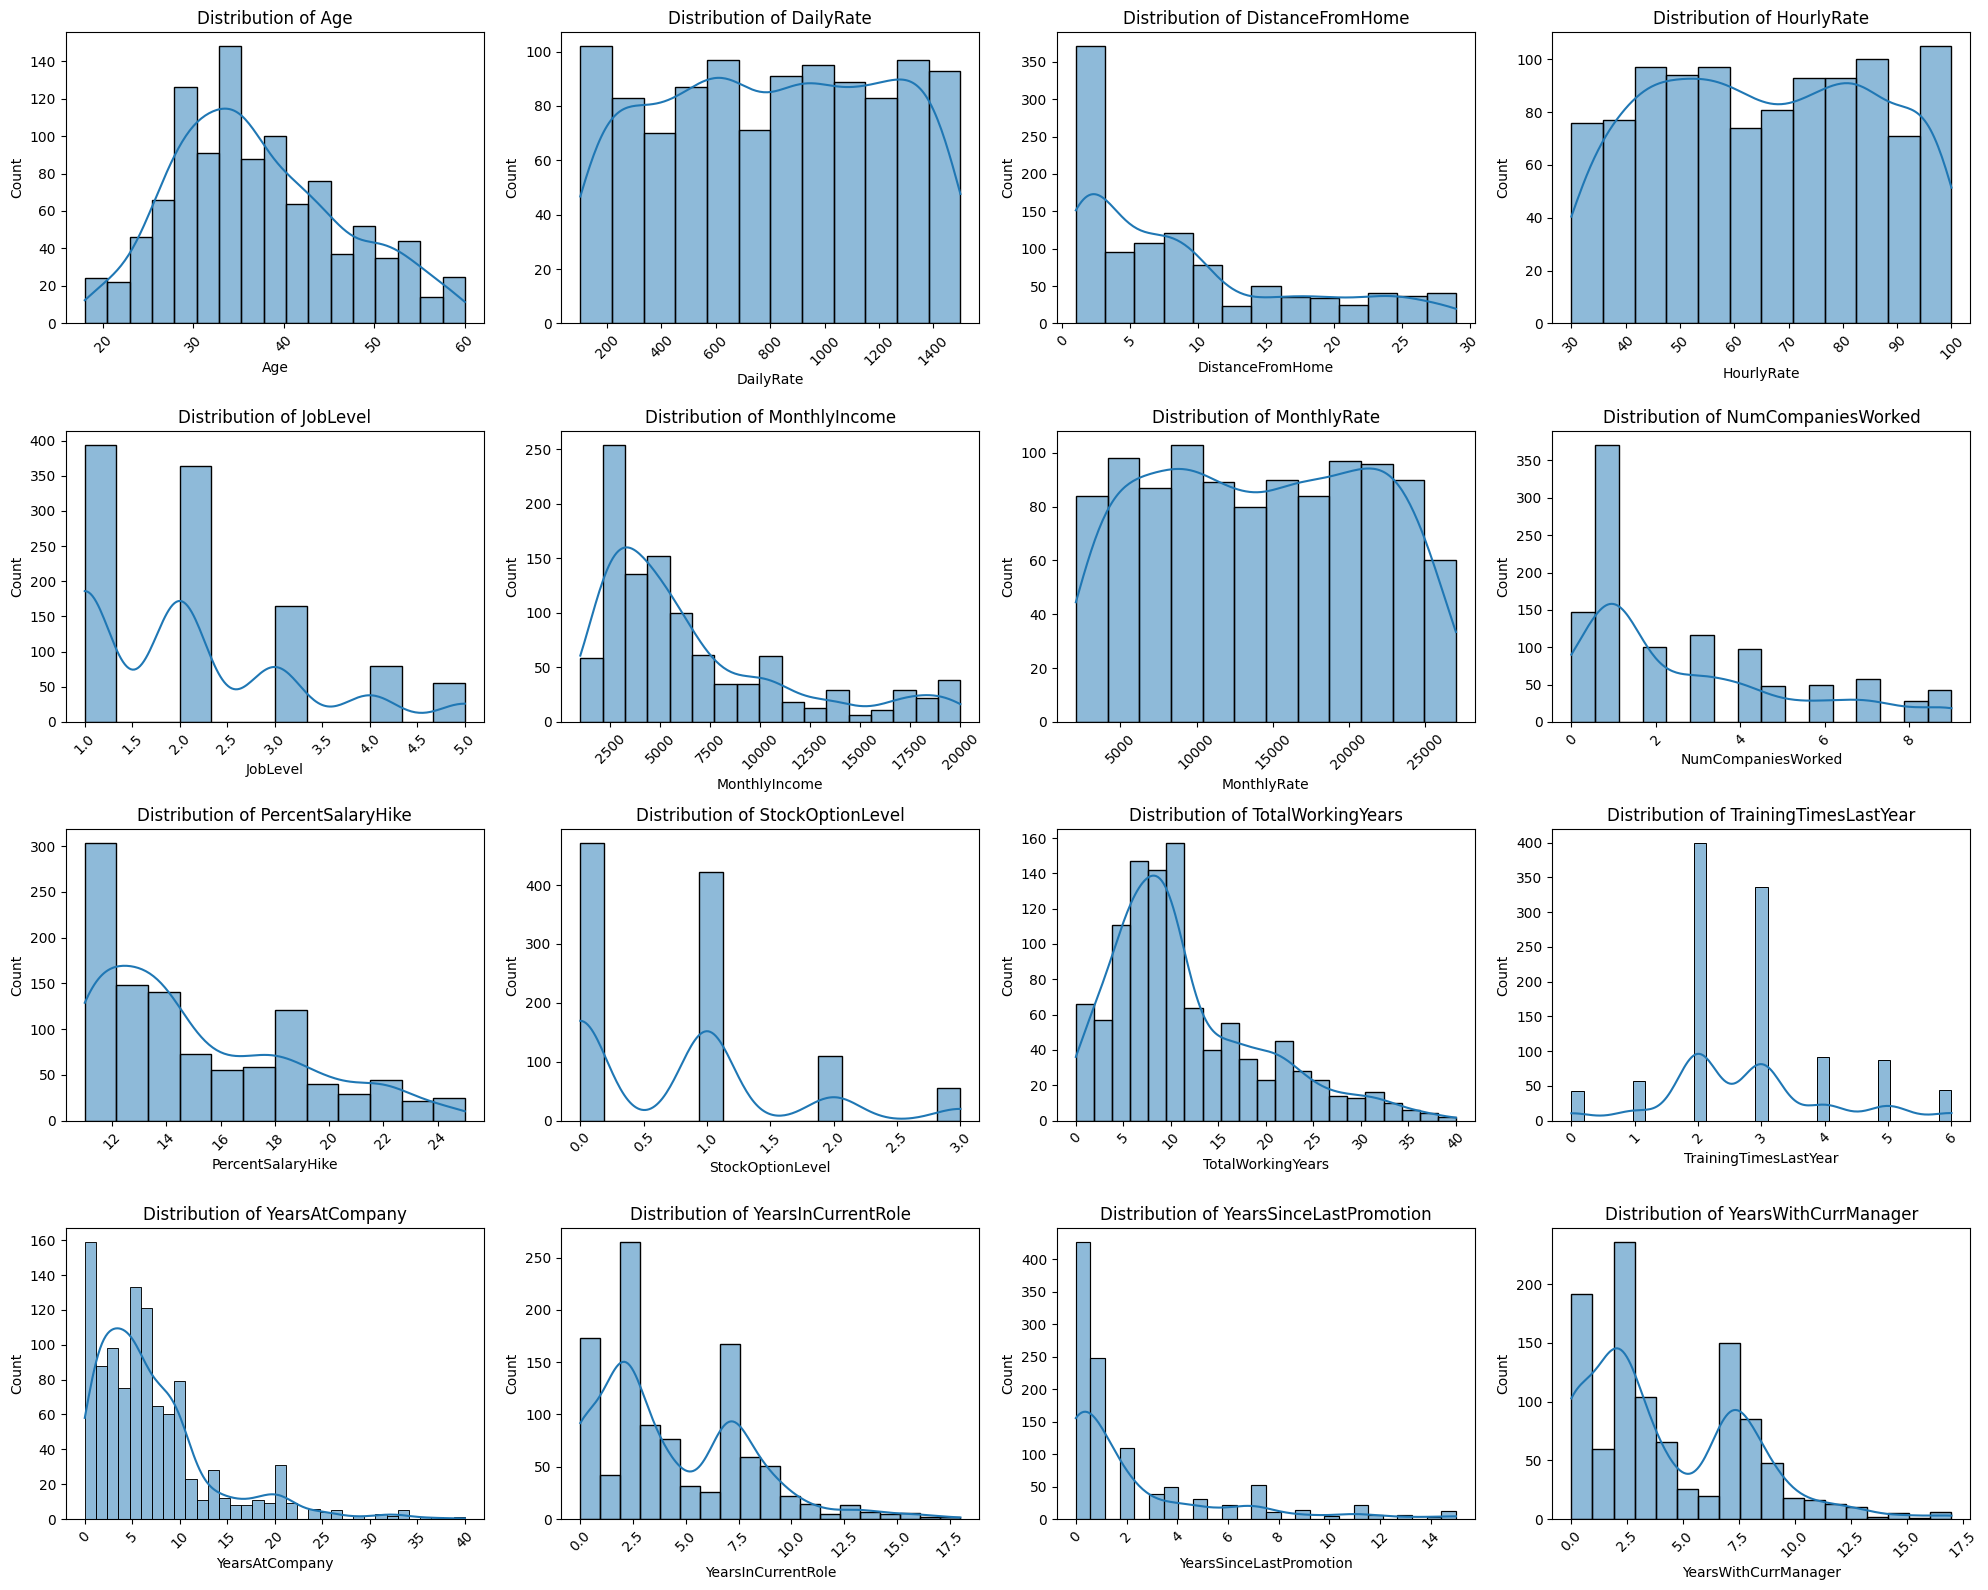

In [195]:
box_cols = [c for c in numerical_cols if c != 'EmployeeId']

ncols = 4
nrows = math.ceil(len(box_cols) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 5, nrows * 4), squeeze=False)
axes = axes.flat

for i, col in enumerate(box_cols):
    sns.histplot(data=clean_df, x=col, kde=True, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')
    axes[i].tick_params(axis='x', rotation=45)

for j in range(len(box_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

#### Distribusi Kategorikal

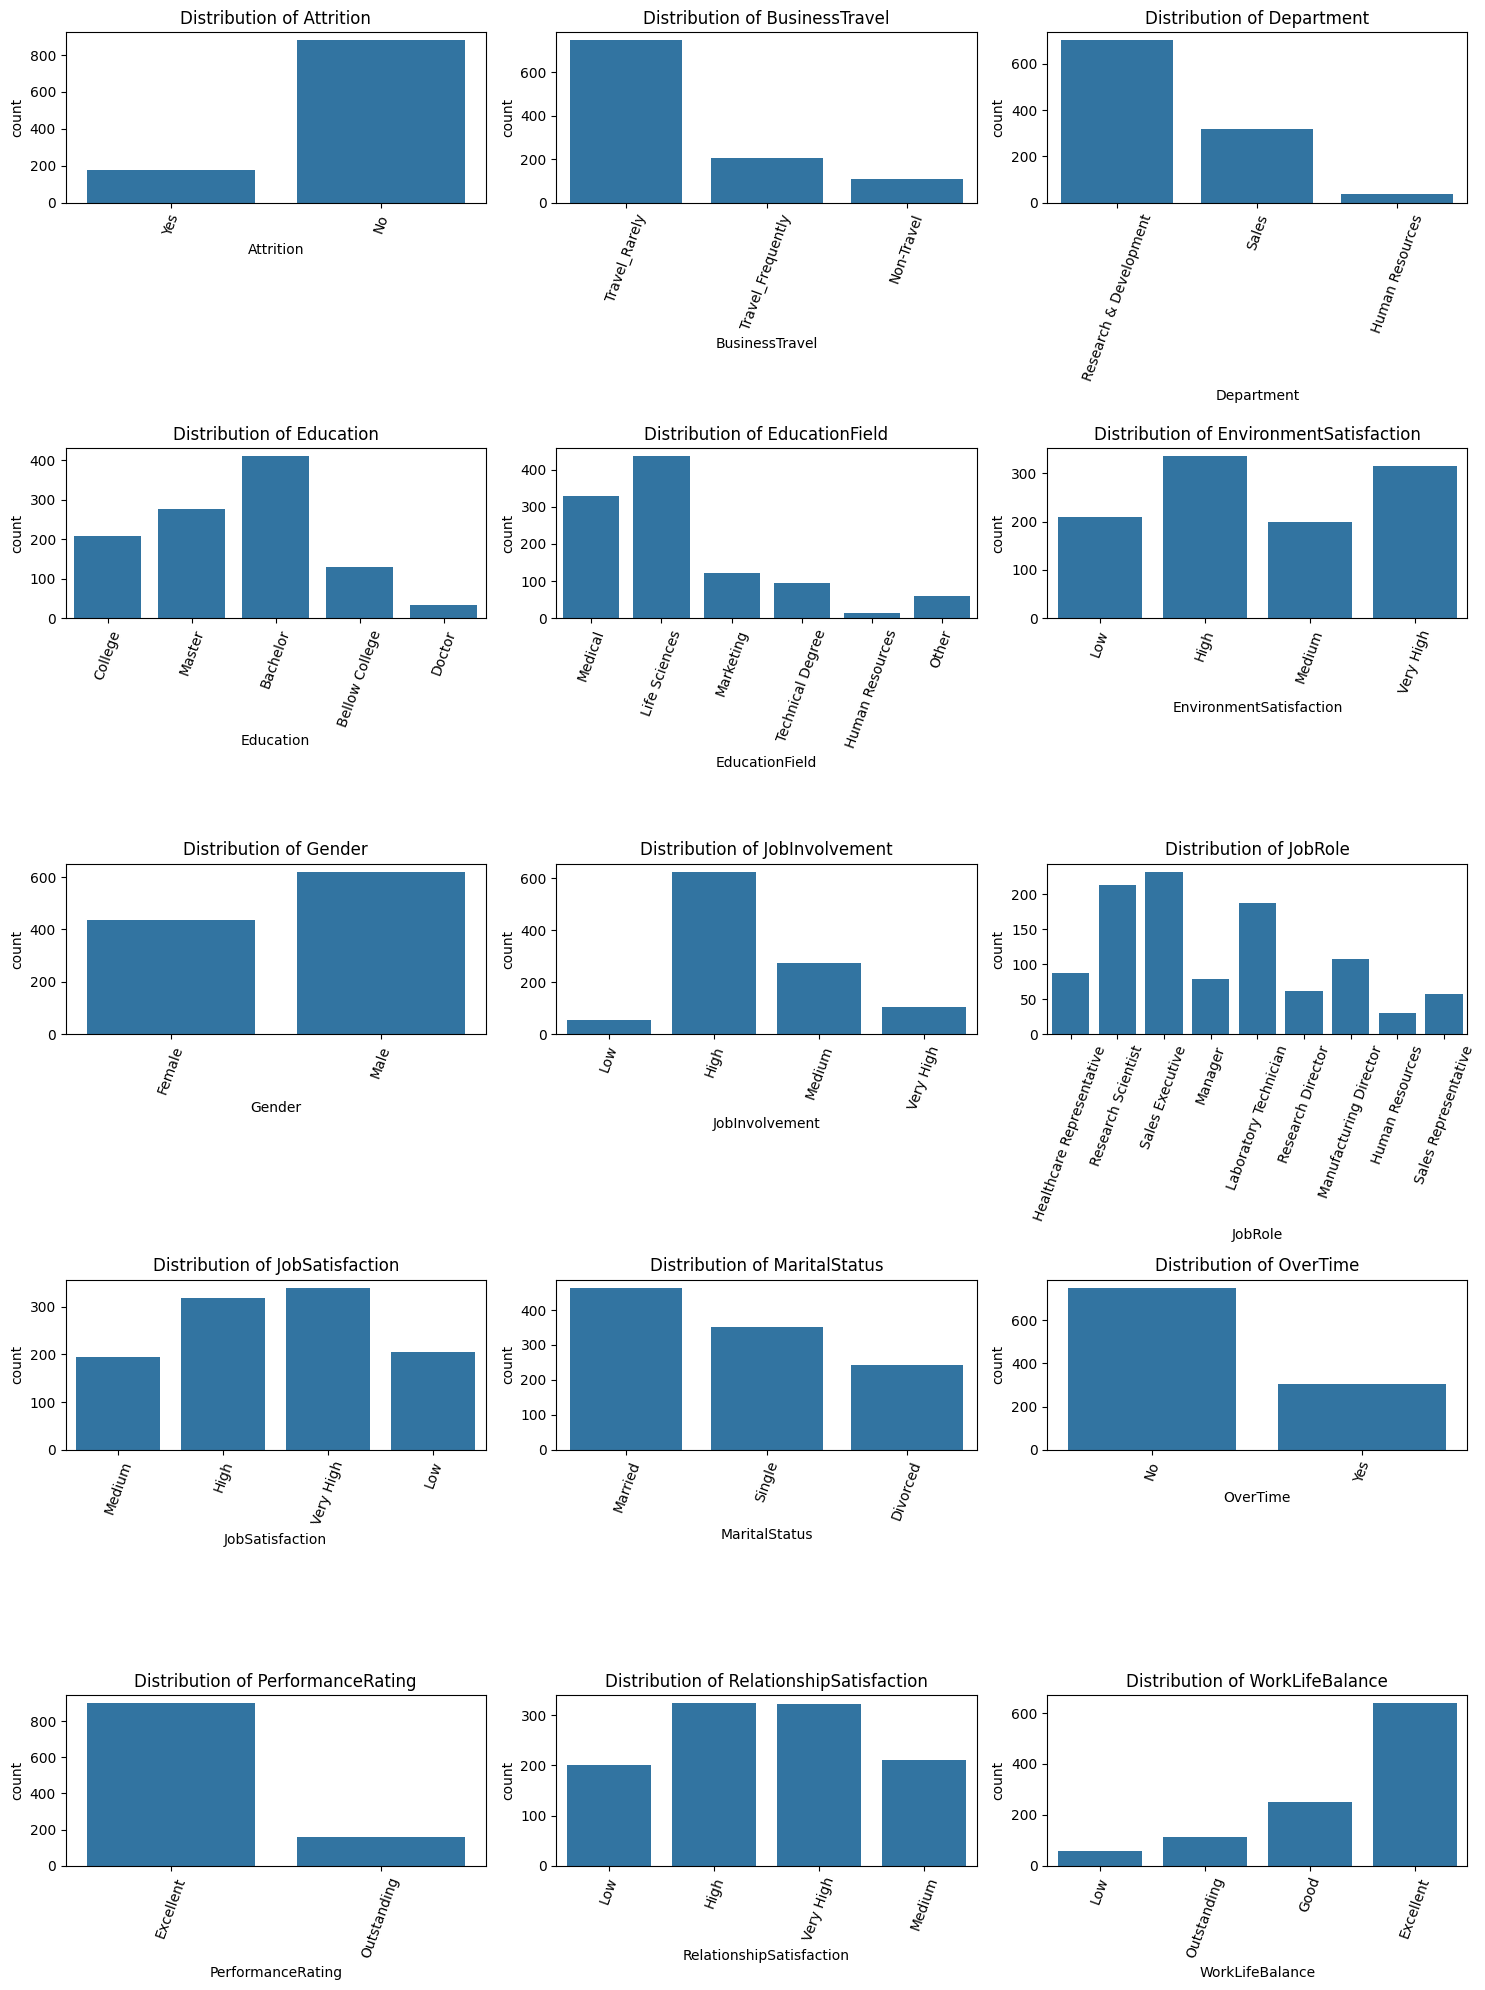

In [196]:
ncols = 3
nrows = math.ceil(len(categorical_cols) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 5, nrows * 4), squeeze=False)
axes = axes.flat

for i, col in enumerate(categorical_cols):
    sns.countplot(data=clean_df, x=col, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')
    axes[i].tick_params(axis='x', rotation=70)

for j in range(len(categorical_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

#### Korelasi Kolom Numerik

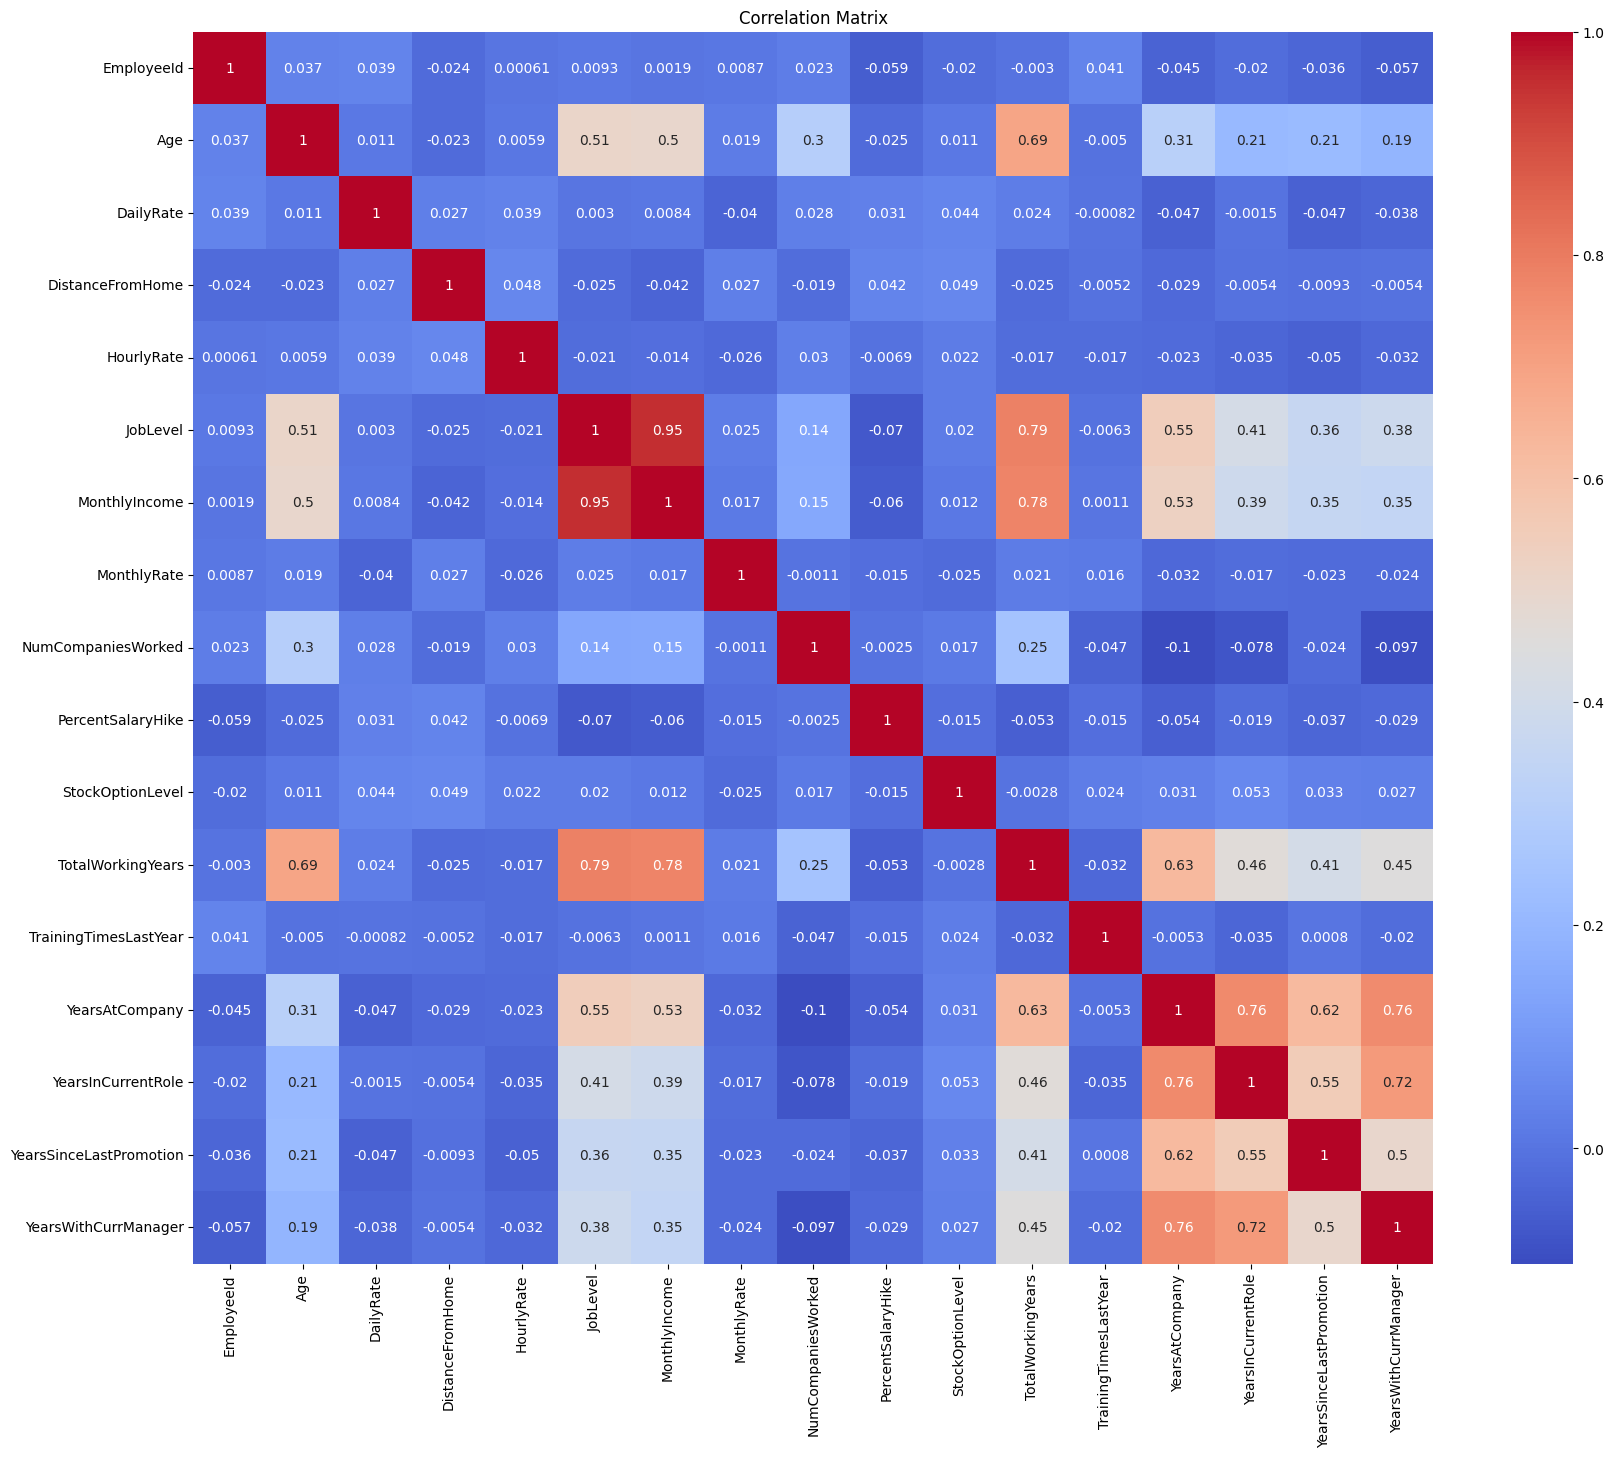

In [197]:
corr_matrix = clean_df[numerical_cols].corr()

plt.figure(figsize=(20,16))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

#### Distribusi Variabel Numerik terhadap Attrition

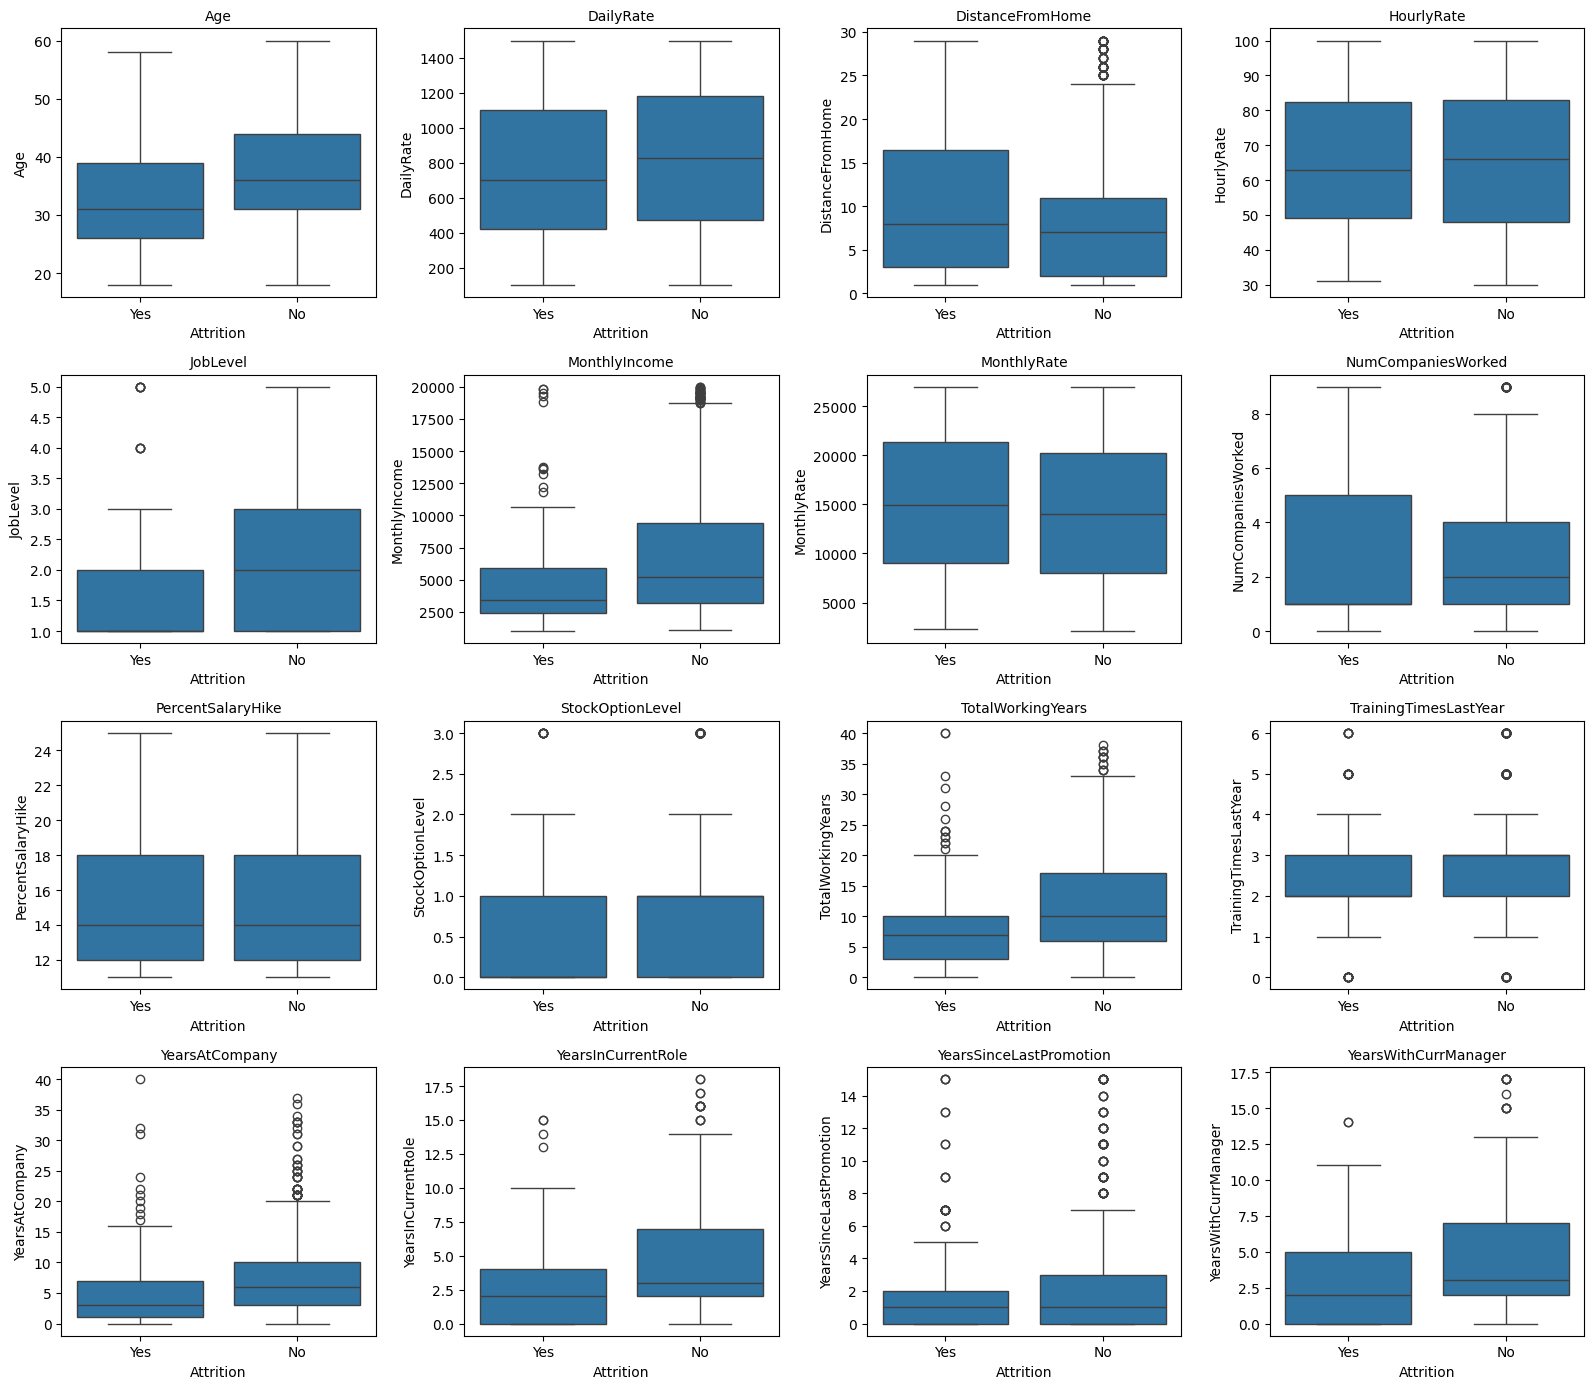

In [198]:
box_cols = [c for c in numerical_cols if c != 'EmployeeId']

ncols = 4
nrows = math.ceil(len(box_cols) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 4, nrows * 3.5), squeeze=False)
axes = axes.flat

for i, col in enumerate(box_cols):
    sns.boxplot(data=clean_df, x='Attrition', y=col, ax=axes[i])
    axes[i].set_title(col, fontsize=10)

for j in range(len(box_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

**Temuan**
* `Age`, `MonthlyIncome`, `TotalWorkingYears`, `JobLevel`, `YearsAtCompany`, `YearsInCurrentRole`, dan `YearsWithCurrManager` menunjukkan **median lebih rendah pada kelompok yang resign (Yes)** dibanding yang bertahan (No).

* Beberapa variabel (`MonthlyIncome`, `TotalWorkingYears`, `YearsAtCompany`, dll) memiliki banyak **outlier** pada kelompok No, mengindikasikan adanya sebagian kecil karyawan dengan nilai jauh di atas rata-rata pada kelompok yang bertahan, kemungkinan mencerminkan karyawan senior/lama.

**Insight**
* Karyawan yang resign cenderung berada di **tahap karier lebih awal**. usia lebih muda, gaji lebih rendah, jabatan lebih rendah, dan masa kerja lebih singkat (baik di perusahaan, di role, maupun dengan manager saat ini).


#### Hubungan Variabel Kategorikal terhadap Attrition

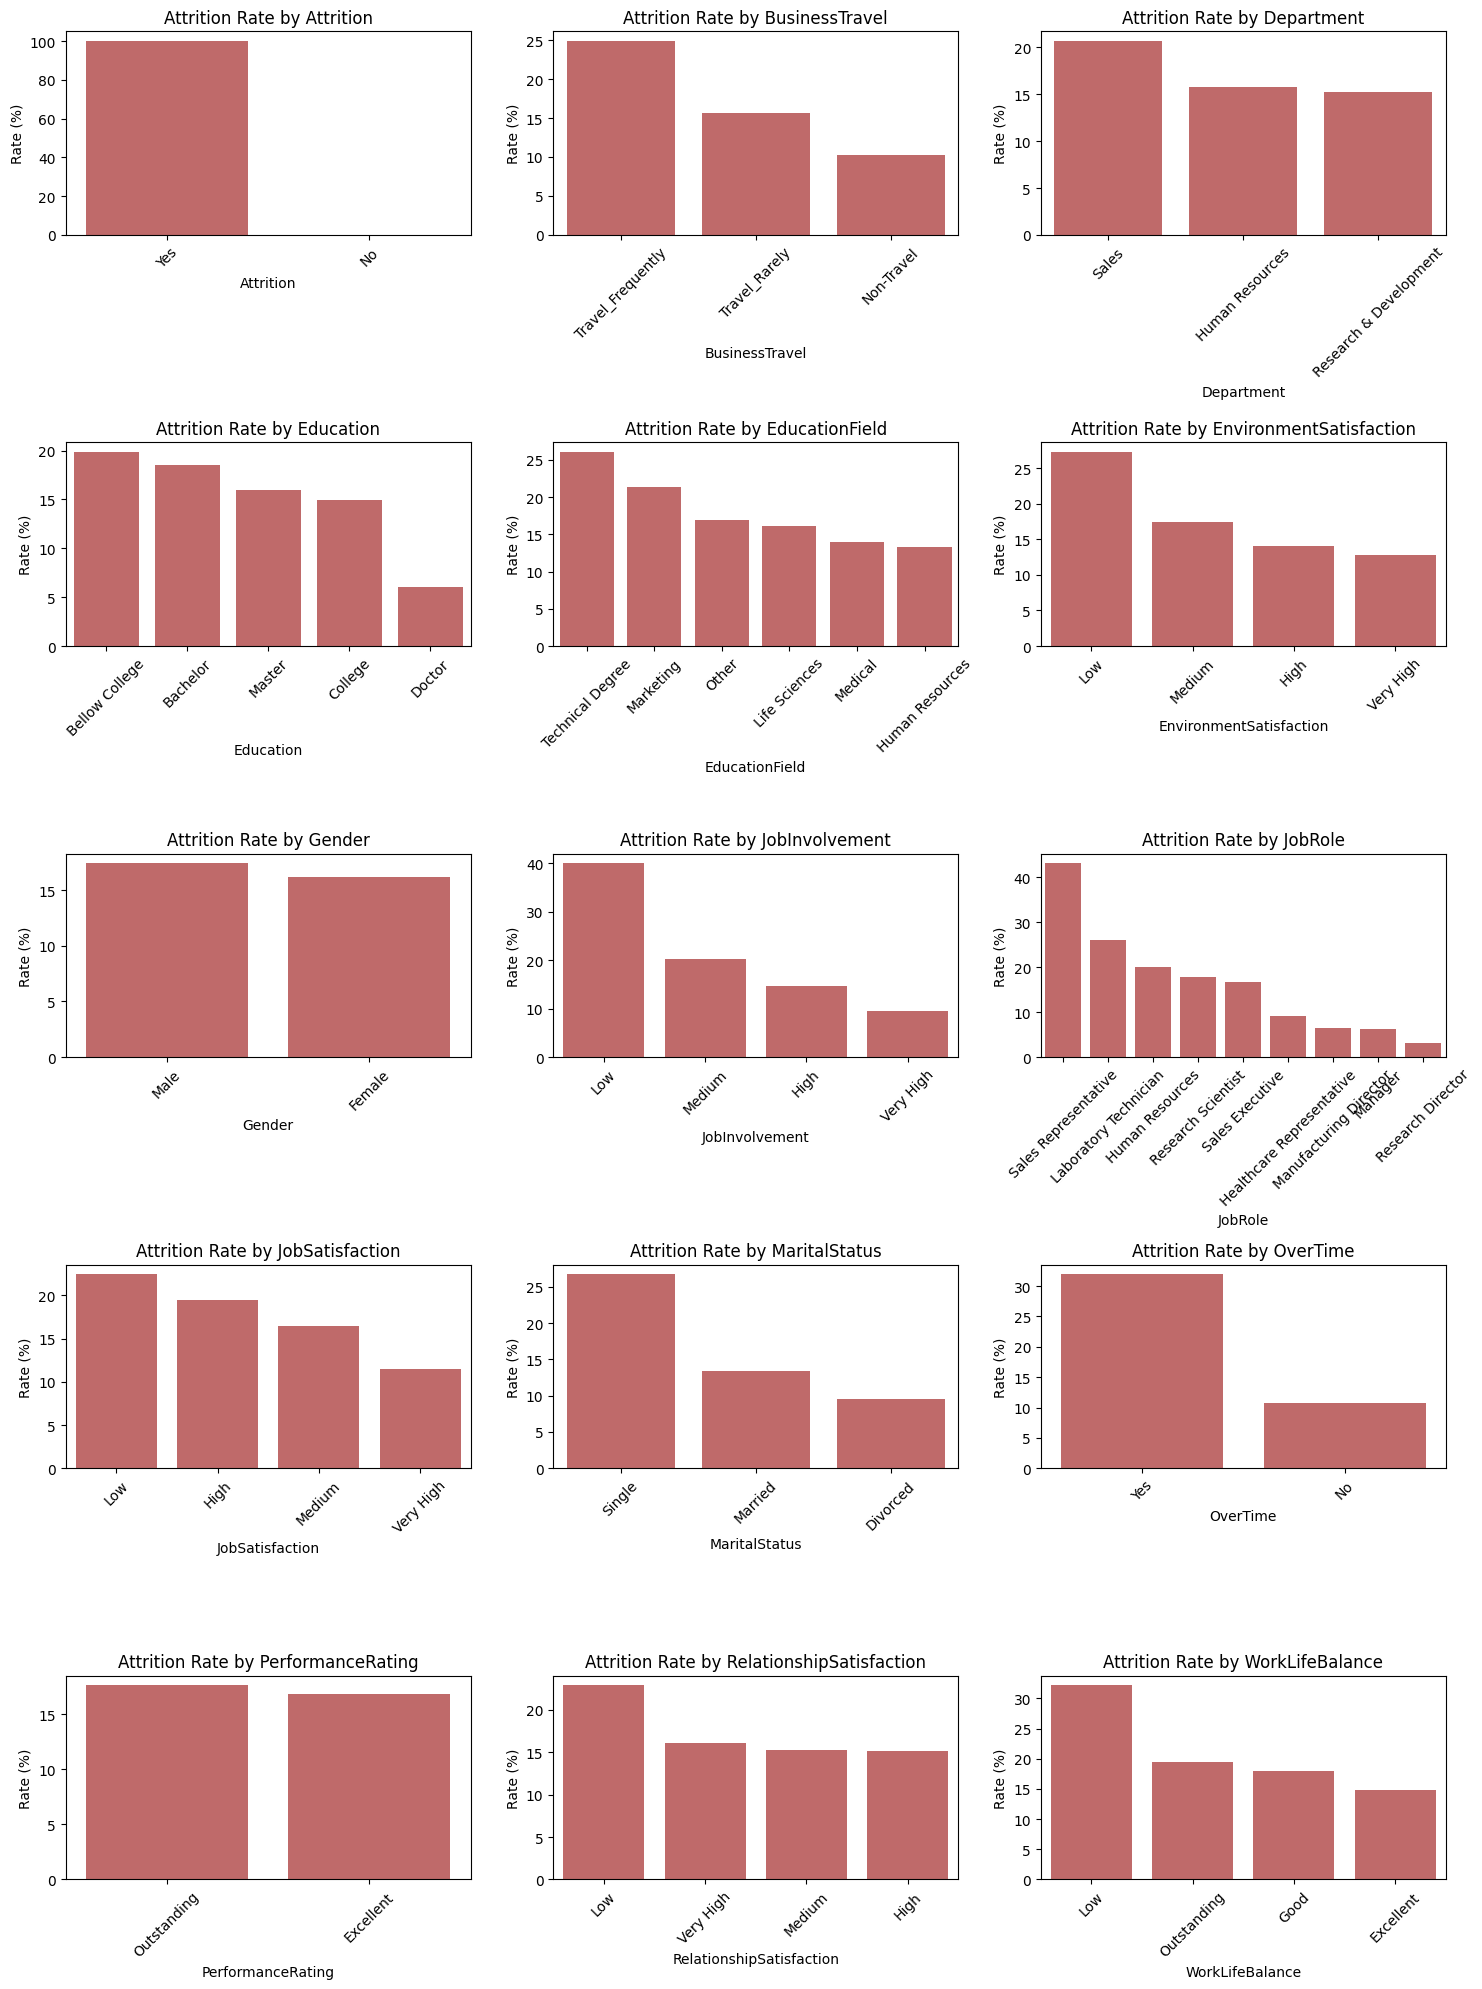

In [199]:
ncols = 3
nrows = math.ceil(len(categorical_cols) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 5, nrows * 4), squeeze=False)
axes = axes.flat

rate_summary = {}
count_summary = {}

for i, col in enumerate(categorical_cols):
    ct = pd.crosstab(clean_df[col], clean_df['Attrition'], normalize='index') * 100
    rate = ct['Yes'].sort_values(ascending=False)   # <- ambil kolom 'Yes' saja, jadi Series 1D
    count = clean_df[col].value_counts()
    rate_summary[col] = rate
    count_summary[col] = count

    sns.barplot(x=rate.index, y=rate.values, ax=axes[i], color='indianred')
    axes[i].set_title(f'Attrition Rate by {col}')
    axes[i].set_ylabel('Rate (%)')
    axes[i].tick_params(axis='x', rotation=45)

for j in range(len(categorical_cols), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

**Temuan**
* `BusinessTravel`, `Department`, `EnvironmentSatisfaction`, `JobInvolvement`, `JobRole`, `JobSatisfaction`, `MaritalStatus`, `OverTime`, `RelationshipSatisfaction`, dan `WorkLifeBalance` memiliki variance yang tinggi terhadap attrition rate.

*  Berdasarkan temuan di atas, analisis selanjutnya difokuskan pada 10 variabel prioritas yang memiliki variansi attrition rate signifikan (mencapai >40%) dan bersifat dapat diintervensi (actionable)

**Insight**
* Faktor internal pekerjaan (beban kerja/lembur, kesesuaian peran, dan lingkungan) serta kondisi individu (status pernikahan dan mobilitas) merupakan pemicu utama keputusan karyawan untuk keluar (attrition).



##### **Hubungan Departemen dan Attrition**

Crosstab Jumlah:
Attrition                No  Yes
Department                      
Human Resources          32    6
Research & Development  594  107
Sales                   253   66

Crosstab Persentase (%):
Attrition                 No   Yes
Department                        
Human Resources         84.2  15.8
Research & Development  84.7  15.3
Sales                   79.3  20.7


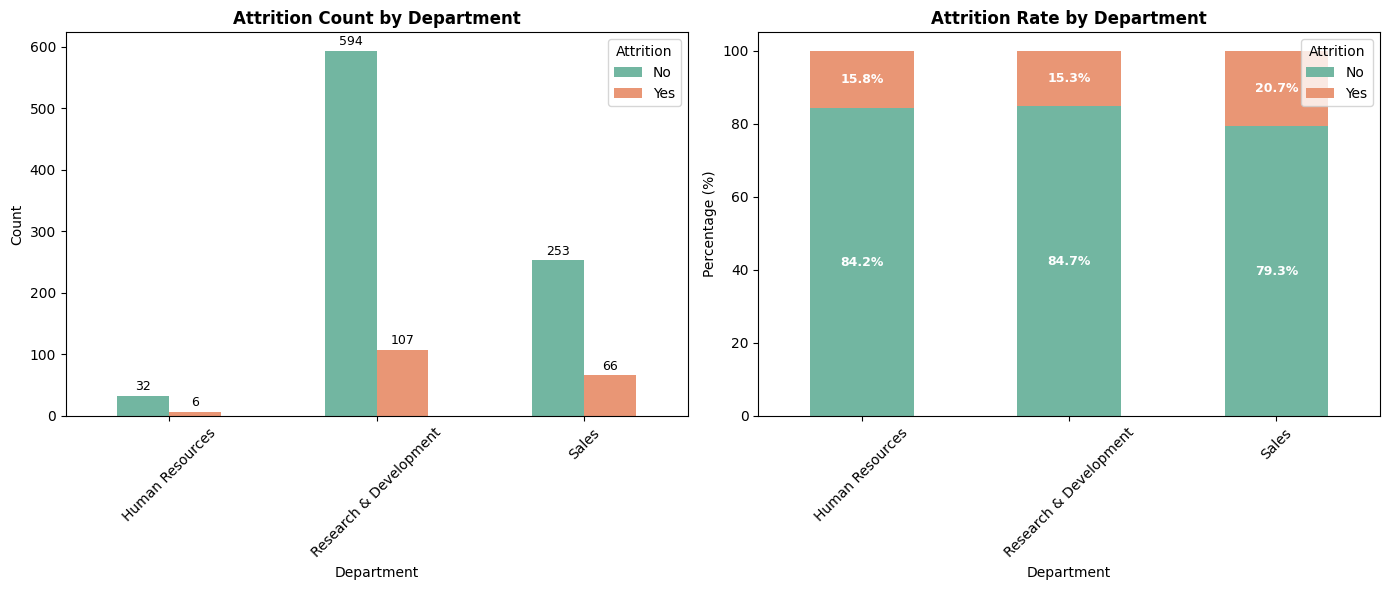

In [200]:
# Crosstab jumlah
crosstab_count = pd.crosstab(clean_df['Department'], clean_df['Attrition'])
print("Crosstab Jumlah:")
print(crosstab_count)

# Crosstab dalam persentase (rate) per Department
crosstab_pct = pd.crosstab(clean_df['Department'], clean_df['Attrition'], normalize='index') * 100
print("\nCrosstab Persentase (%):")
print(crosstab_pct.round(1))

# 2 subplot
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Subplot 1: Count
crosstab_count.plot(kind='bar', stacked=False, ax=axes[0],
                     color=['#72B6A1', '#E99675'])
axes[0].set_title('Attrition Count by Department', fontweight='bold')
axes[0].set_ylabel('Count')
axes[0].set_xlabel('Department')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(title='Attrition', labels=['No', 'Yes'])

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%d', padding=2, fontsize=9)

# Subplot 2: Rate
crosstab_pct.plot(kind='bar', stacked=True, ax=axes[1],
                   color=['#72B6A1', '#E99675'])
axes[1].set_title('Attrition Rate by Department', fontweight='bold')
axes[1].set_ylabel('Percentage (%)')
axes[1].set_xlabel('Department')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(title='Attrition', labels=['No', 'Yes'])

for container in axes[1].containers:
    labels = [f'{v:.1f}%' if v > 0 else '' for v in container.datavalues]
    axes[1].bar_label(container, labels=labels, label_type='center',
                       fontsize=9, color='white', fontweight='bold')

plt.tight_layout()
plt.show()

**Temuan**
* Department **Sales** memiliki Attrition rate tertinggi sebesar **20.7%** dibanding **Research & Development (15.3)** dan **Human Resources (15.8%)**
* Departement **Research & Development** menyumbang jumlah karyawan terbanyak secara absolut (107 orang), karena memiliki karyawan terbanyak sebesar 701 karyawan.

**Insight**
* Attrition rate sebesar **20.7%** pada Department **Sales** mengindikasikan terdapat masalah retensi yang lebih serius dibanding department lain


##### **Hubungan Overtime dengan Attrition**

Crosstab Jumlah:
Attrition   No  Yes
OverTime           
No         670   81
Yes        209   98

Crosstab Persentase (%):
Attrition    No   Yes
OverTime             
No         89.2  10.8
Yes        68.1  31.9


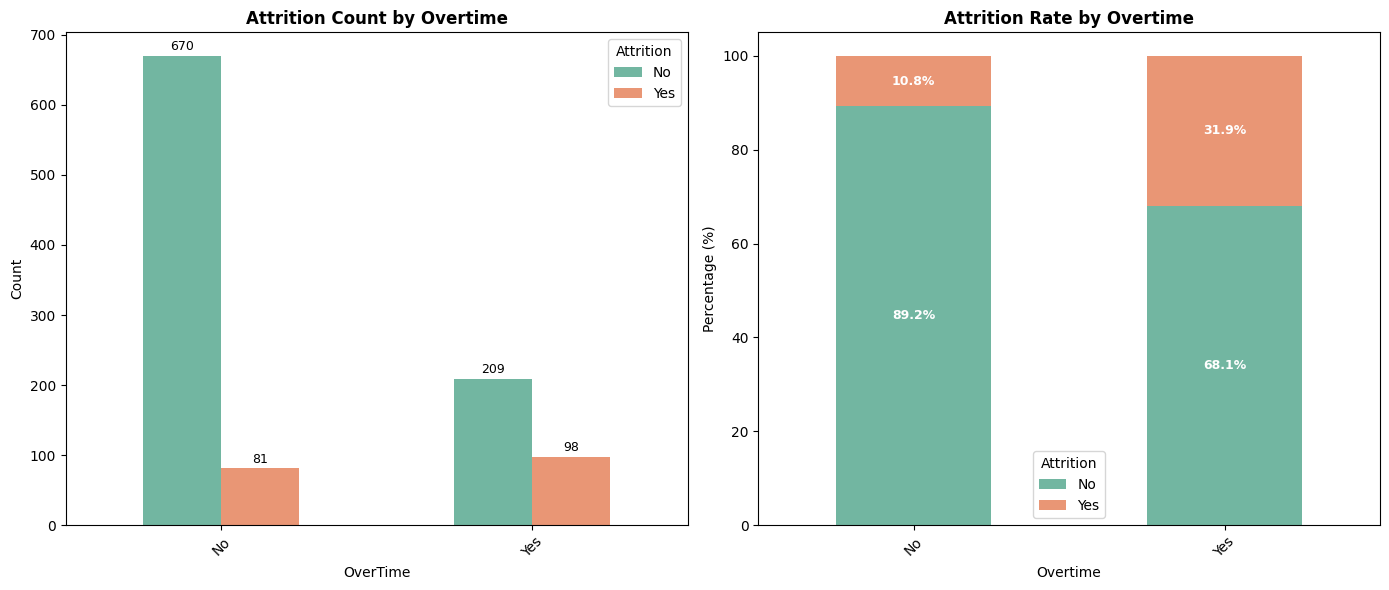

In [201]:
# Crosstab jumlah
crosstab_count = pd.crosstab(clean_df['OverTime'], clean_df['Attrition'])
print("Crosstab Jumlah:")
print(crosstab_count)

# Crosstab dalam persentase (rate) per Overtime
crosstab_pct = pd.crosstab(clean_df['OverTime'], clean_df['Attrition'], normalize='index') * 100
print("\nCrosstab Persentase (%):")
print(crosstab_pct.round(1))

# 2 subplot
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Subplot 1: Count
crosstab_count.plot(kind='bar', stacked=False, ax=axes[0],
                     color=['#72B6A1', '#E99675'])
axes[0].set_title('Attrition Count by Overtime', fontweight='bold')
axes[0].set_ylabel('Count')
axes[0].set_xlabel('OverTime')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(title='Attrition', labels=['No', 'Yes'])

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%d', padding=2, fontsize=9)

# Subplot 2: Rate
crosstab_pct.plot(kind='bar', stacked=True, ax=axes[1],
                   color=['#72B6A1', '#E99675'])
axes[1].set_title('Attrition Rate by Overtime', fontweight='bold')
axes[1].set_ylabel('Percentage (%)')
axes[1].set_xlabel('Overtime')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(title='Attrition', labels=['No', 'Yes'])

for container in axes[1].containers:
    labels = [f'{v:.1f}%' if v > 0 else '' for v in container.datavalues]
    axes[1].bar_label(container, labels=labels, label_type='center',
                       fontsize=9, color='white', fontweight='bold')

plt.tight_layout()
plt.show()

**Temuan**
* Karyawan yang lembur memiliki attrition rate sebesar 31.9%, jauh lebih tinggi dibanding yang tidak lembur (10.8%).

**Insight**
* OverTime menjadi salah satu faktor risiko attrition terkuat, rate-nya hampir 3x lipat dibanding non-overtime, sehingga beban kerja berlebih (burnout) patut diduga sebagai salah satu pendorong utama resign.

##### **Hubungan BusinessTravel dengan Attrition**

Crosstab Jumlah:
Attrition           No  Yes
BusinessTravel             
Non-Travel          96   11
Travel_Frequently  154   51
Travel_Rarely      629  117

Crosstab Persentase (%):
Attrition            No   Yes
BusinessTravel               
Non-Travel         89.7  10.3
Travel_Frequently  75.1  24.9
Travel_Rarely      84.3  15.7


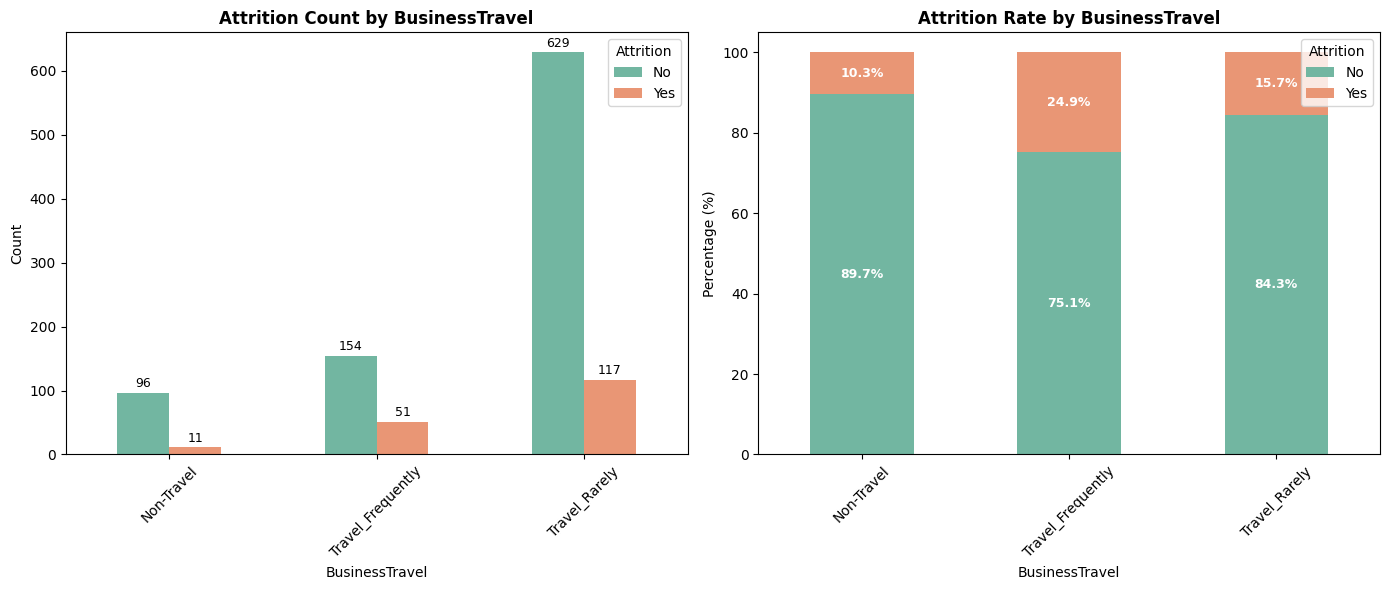

In [202]:
# Crosstab jumlah
crosstab_count = pd.crosstab(clean_df['BusinessTravel'], clean_df['Attrition'])
print("Crosstab Jumlah:")
print(crosstab_count)

# Crosstab dalam persentase (rate) per BusinessTravel
crosstab_pct = pd.crosstab(clean_df['BusinessTravel'], clean_df['Attrition'], normalize='index') * 100
print("\nCrosstab Persentase (%):")
print(crosstab_pct.round(1))

# 2 subplot
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Subplot 1: Count
crosstab_count.plot(kind='bar', stacked=False, ax=axes[0],
                     color=['#72B6A1', '#E99675'])
axes[0].set_title('Attrition Count by BusinessTravel', fontweight='bold')
axes[0].set_ylabel('Count')
axes[0].set_xlabel('BusinessTravel')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(title='Attrition', labels=['No', 'Yes'])

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%d', padding=2, fontsize=9)

# Subplot 2: Rate
crosstab_pct.plot(kind='bar', stacked=True, ax=axes[1],
                   color=['#72B6A1', '#E99675'])
axes[1].set_title('Attrition Rate by BusinessTravel', fontweight='bold')
axes[1].set_ylabel('Percentage (%)')
axes[1].set_xlabel('BusinessTravel')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(title='Attrition', labels=['No', 'Yes'])

for container in axes[1].containers:
    labels = [f'{v:.1f}%' if v > 0 else '' for v in container.datavalues]
    axes[1].bar_label(container, labels=labels, label_type='center',
                       fontsize=9, color='white', fontweight='bold')

plt.tight_layout()
plt.show()

**Temuan**
* Karyawan yang sering melakukan perjalanan bisnis **(Travel_Frequently)** memiliki attrition rate tertinggi sebesar **24.9%**, dibanding **Travel_Rarely (15.7%)** dan **Non-Travel (10.3%).**
* Secara absolut, **Travel_Rarely** menyumbang jumlah resign terbanyak (117 orang), karena kelompok ini yang terbesar (746 karyawan).

**Insight**
* Frekuensi perjalanan bisnis berbanding lurus dengan attrition rate, semakin sering travel, semakin tinggi risiko resign, mengindikasikan kelelahan/gangguan work-life balance akibat perjalanan dinas sebagai salah satu pendorong retensi yang perlu dipertimbangkan.

##### **Hubungan JobRole dengan Attrition**

Crosstab Jumlah:
Attrition                   No  Yes
JobRole                            
Healthcare Representative   80    8
Human Resources             24    6
Laboratory Technician      139   49
Manager                     74    5
Manufacturing Director     100    7
Research Director           60    2
Research Scientist         176   38
Sales Executive            193   39
Sales Representative        33   25

Crosstab Persentase (%):
Attrition                    No   Yes
JobRole                              
Healthcare Representative  90.9   9.1
Human Resources            80.0  20.0
Laboratory Technician      73.9  26.1
Manager                    93.7   6.3
Manufacturing Director     93.5   6.5
Research Director          96.8   3.2
Research Scientist         82.2  17.8
Sales Executive            83.2  16.8
Sales Representative       56.9  43.1


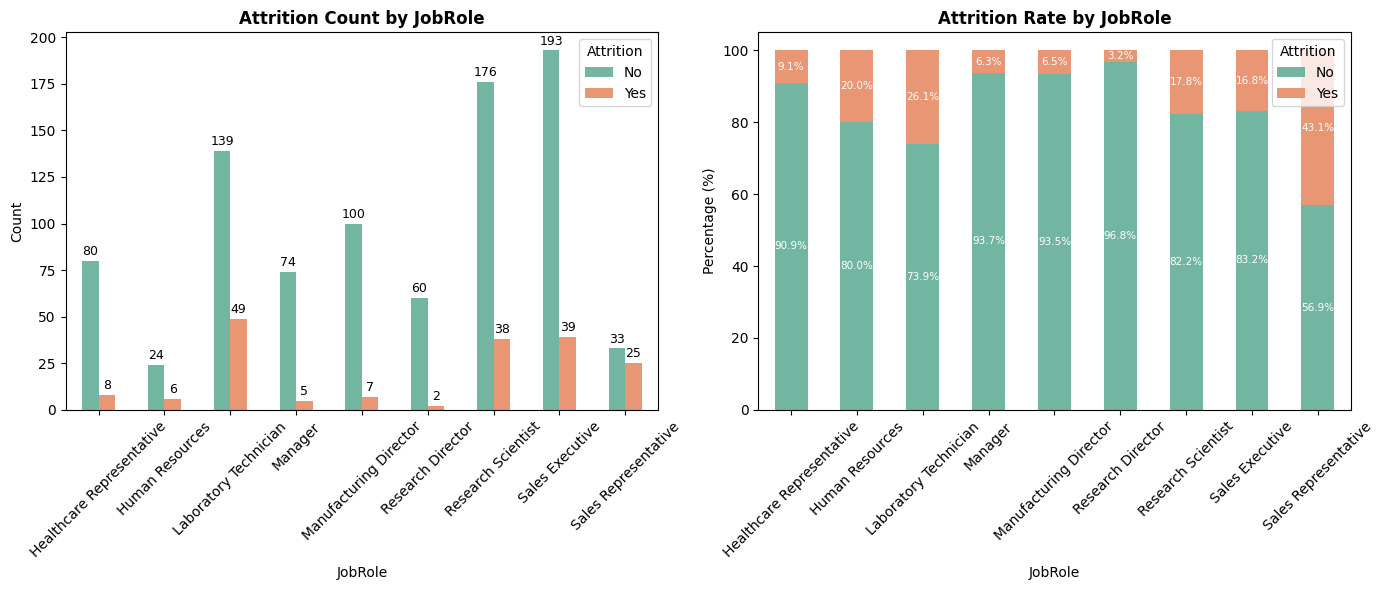

In [203]:
# Crosstab jumlah
crosstab_count = pd.crosstab(clean_df['JobRole'], clean_df['Attrition'])
print("Crosstab Jumlah:")
print(crosstab_count)

# Crosstab dalam persentase (rate) per JobRole
crosstab_pct = pd.crosstab(clean_df['JobRole'], clean_df['Attrition'], normalize='index') * 100
print("\nCrosstab Persentase (%):")
print(crosstab_pct.round(1))

# 2 subplot
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Subplot 1: Count
crosstab_count.plot(kind='bar', stacked=False, ax=axes[0],
                     color=['#72B6A1', '#E99675'])
axes[0].set_title('Attrition Count by JobRole', fontweight='bold')
axes[0].set_ylabel('Count')
axes[0].set_xlabel('JobRole')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(title='Attrition', labels=['No', 'Yes'])

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%d', padding=2, fontsize=9)

# Subplot 2: Rate
crosstab_pct.plot(kind='bar', stacked=True, ax=axes[1],
                   color=['#72B6A1', '#E99675'])
axes[1].set_title('Attrition Rate by JobRole', fontweight='bold')
axes[1].set_ylabel('Percentage (%)')
axes[1].set_xlabel('JobRole')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(title='Attrition', labels=['No', 'Yes'])

for container in axes[1].containers:
    labels = [f'{v:.1f}%' if v > 0 else '' for v in container.datavalues]
    axes[1].bar_label(container, labels=labels, label_type='center',
                       fontsize=7.5, color='white')

plt.tight_layout()
plt.show()

**Temuan**
* *Sales Representative memiliki attrition rate tertinggi di antara semua JobRole, yaitu 43.1%. Jauh di atas rata-rata role lainnya.
* Role dengan attrition rate terendah didominasi oleh posisi direktur/manajerial yaitu Research Director (3.2%), Manager (6.3%), dan Manufacturing Director (6.5%).
* Menariknya, dalam satu fungsi yang sama (Sales), ada kesenjangan besar antara Sales Representative (43.1%) dan Sales Executive (16.8%), perbedaan hampir 2.6x meskipun keduanya sama-sama "sales".

**Insight**
* Jabatan-jabatan dengan orientasi target kinerja tinggi atau operasional langsung di lapangan tampak berasosiasi dengan tekanan kerja yang lebih besar, yang berpotensi turut mendorong tingkat attrition yang lebih tinggi pada jabatan tersebut.
* Pola "role senior/managerial → attrition rendah" konsisten dengan intuisi umum di HR analytics: posisi dengan kompensasi lebih tinggi, kestabilan karier, dan otoritas lebih besar biasanya punya retention lebih baik.

#####  **Hubungan MaritalStatus dengan Attrition**

Crosstab Jumlah:
Attrition       No  Yes
MaritalStatus          
Divorced       219   23
Married        402   62
Single         258   94

Crosstab Persentase (%):
Attrition        No   Yes
MaritalStatus            
Divorced       90.5   9.5
Married        86.6  13.4
Single         73.3  26.7


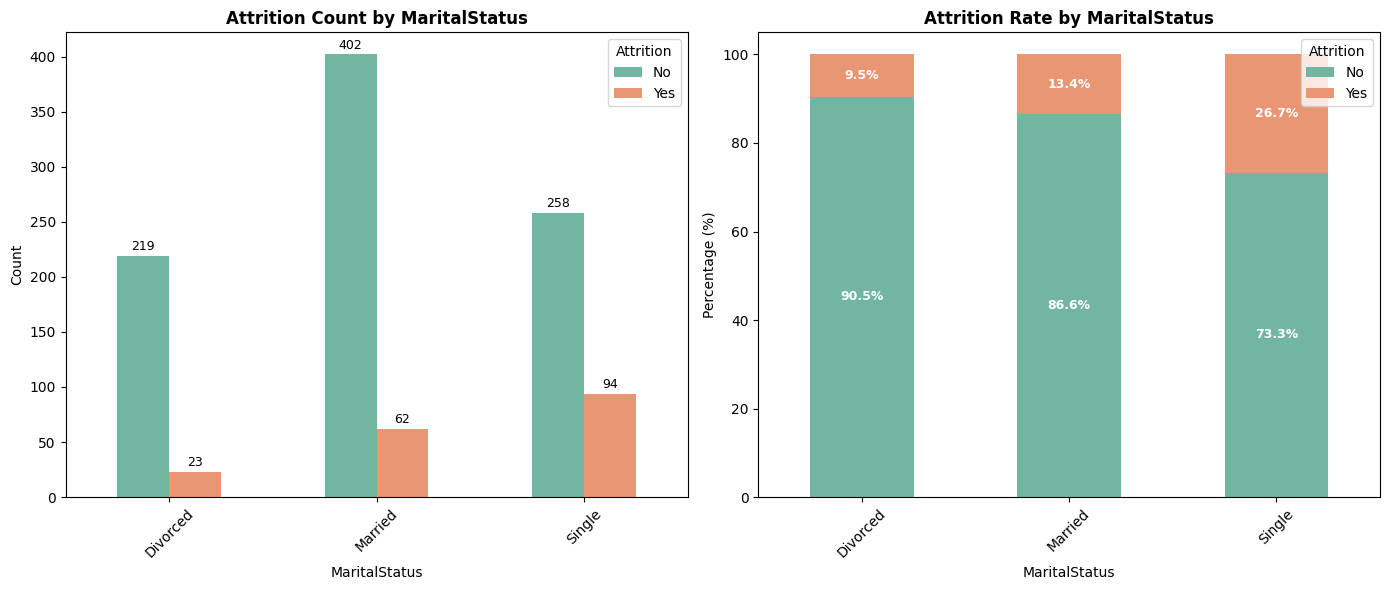

In [204]:
# Crosstab jumlah
crosstab_count = pd.crosstab(clean_df['MaritalStatus'], clean_df['Attrition'])
print("Crosstab Jumlah:")
print(crosstab_count)

# Crosstab dalam persentase (rate) per MaritalStatus
crosstab_pct = pd.crosstab(clean_df['MaritalStatus'], clean_df['Attrition'], normalize='index') * 100
print("\nCrosstab Persentase (%):")
print(crosstab_pct.round(1))

# 2 subplot
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Subplot 1: Count
crosstab_count.plot(kind='bar', stacked=False, ax=axes[0],
                     color=['#72B6A1', '#E99675'])
axes[0].set_title('Attrition Count by MaritalStatus', fontweight='bold')
axes[0].set_ylabel('Count')
axes[0].set_xlabel('MaritalStatus')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(title='Attrition', labels=['No', 'Yes'])

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%d', padding=2, fontsize=9)

# Subplot 2: Rate
crosstab_pct.plot(kind='bar', stacked=True, ax=axes[1],
                   color=['#72B6A1', '#E99675'])
axes[1].set_title('Attrition Rate by MaritalStatus', fontweight='bold')
axes[1].set_ylabel('Percentage (%)')
axes[1].set_xlabel('MaritalStatus')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(title='Attrition', labels=['No', 'Yes'])

for container in axes[1].containers:
    labels = [f'{v:.1f}%' if v > 0 else '' for v in container.datavalues]
    axes[1].bar_label(container, labels=labels, label_type='center',
                       fontsize=9, color='white', fontweight='bold')

plt.tight_layout()
plt.show()

**Temuan**
* Single memiliki attrition rate tertinggi (26.7%), diikuti Married (13.4%) dan Divorced (9.5%).
* Selisihnya cukup besar, attrition rate Single 2.8x lebih tinggi dibanding Divorced.

**Insight**
* Status Single kemungkinan berkorelasi dengan usia yang lebih muda dan fase awal karier, sehingga attrition rate-nya lebih tinggi, konsisten dengan pola seniority yang ditemukan pada JobRole. Karyawan Married atau Divorced cenderung lebih stabil, kemungkinan didorong oleh faktor struktural seperti tanggungan keluarga dan kebutuhan stabilitas ekonomi.

##### **Hubungan EnvirontmentSatisfaction dengan Attrition**

Crosstab Jumlah:
Attrition                 No  Yes
EnvironmentSatisfaction          
High                     288   47
Low                      152   57
Medium                   165   35
Very High                274   40

Crosstab Persentase (%):
Attrition                  No   Yes
EnvironmentSatisfaction            
High                     86.0  14.0
Low                      72.7  27.3
Medium                   82.5  17.5
Very High                87.3  12.7


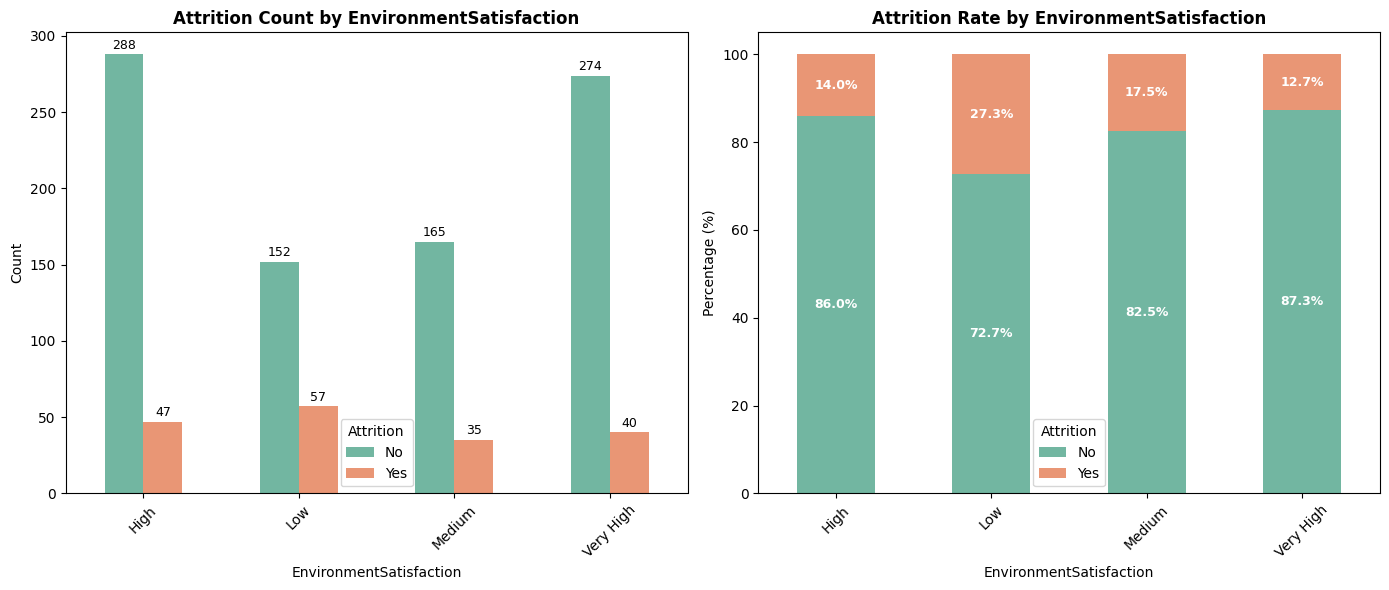

In [205]:
# Crosstab jumlah
crosstab_count = pd.crosstab(clean_df['EnvironmentSatisfaction'], clean_df['Attrition'])
print("Crosstab Jumlah:")
print(crosstab_count)

# Crosstab dalam persentase (rate) per EnvironmentSatisfaction
crosstab_pct = pd.crosstab(clean_df['EnvironmentSatisfaction'], clean_df['Attrition'], normalize='index') * 100
print("\nCrosstab Persentase (%):")
print(crosstab_pct.round(1))

# 2 subplot
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Subplot 1: Count
crosstab_count.plot(kind='bar', stacked=False, ax=axes[0],
                     color=['#72B6A1', '#E99675'])
axes[0].set_title('Attrition Count by EnvironmentSatisfaction', fontweight='bold')
axes[0].set_ylabel('Count')
axes[0].set_xlabel('EnvironmentSatisfaction')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(title='Attrition', labels=['No', 'Yes'])

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%d', padding=2, fontsize=9)

# Subplot 2: Rate
crosstab_pct.plot(kind='bar', stacked=True, ax=axes[1],
                   color=['#72B6A1', '#E99675'])
axes[1].set_title('Attrition Rate by EnvironmentSatisfaction', fontweight='bold')
axes[1].set_ylabel('Percentage (%)')
axes[1].set_xlabel('EnvironmentSatisfaction')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(title='Attrition', labels=['No', 'Yes'])

for container in axes[1].containers:
    labels = [f'{v:.1f}%' if v > 0 else '' for v in container.datavalues]
    axes[1].bar_label(container, labels=labels, label_type='center',
                       fontsize=9, color='white', fontweight='bold')

plt.tight_layout()
plt.show()

**Temuan**
* Karyawan dengan **EnvironmentSatisfaction Low** memiliki attrition rate yang tinggi yaitu sebesar **27.3%**, sedangkan karyawan dengan **EnvironmentSatisfaction Very High** memiliki Attrition rate yang rendah sebesar **12.7%**
* Polanya bersifat monoton, attrition rate menurun secara konsisten seiring naiknya level kepuasan (Low 27.3% → Medium 17.5% → High 14.0% → Very High 12.7%)

**Insight**
* Terdapat hubungan yang kuat dan konsisten antara EnvironmentSatisfaction yang rendah dengan attrition rate yang lebih tinggi. Pola ini mengindikasikan kepuasan terhadap lingkungan kerja sebagai salah satu faktor risiko potensial.

##### **Hubungan JobInvolvement dengan Attrition**

Crosstab Jumlah:
Attrition        No  Yes
JobInvolvement          
High            533   92
Low              33   22
Medium          218   55
Very High        95   10

Crosstab Persentase (%):
Attrition         No   Yes
JobInvolvement            
High            85.3  14.7
Low             60.0  40.0
Medium          79.9  20.1
Very High       90.5   9.5


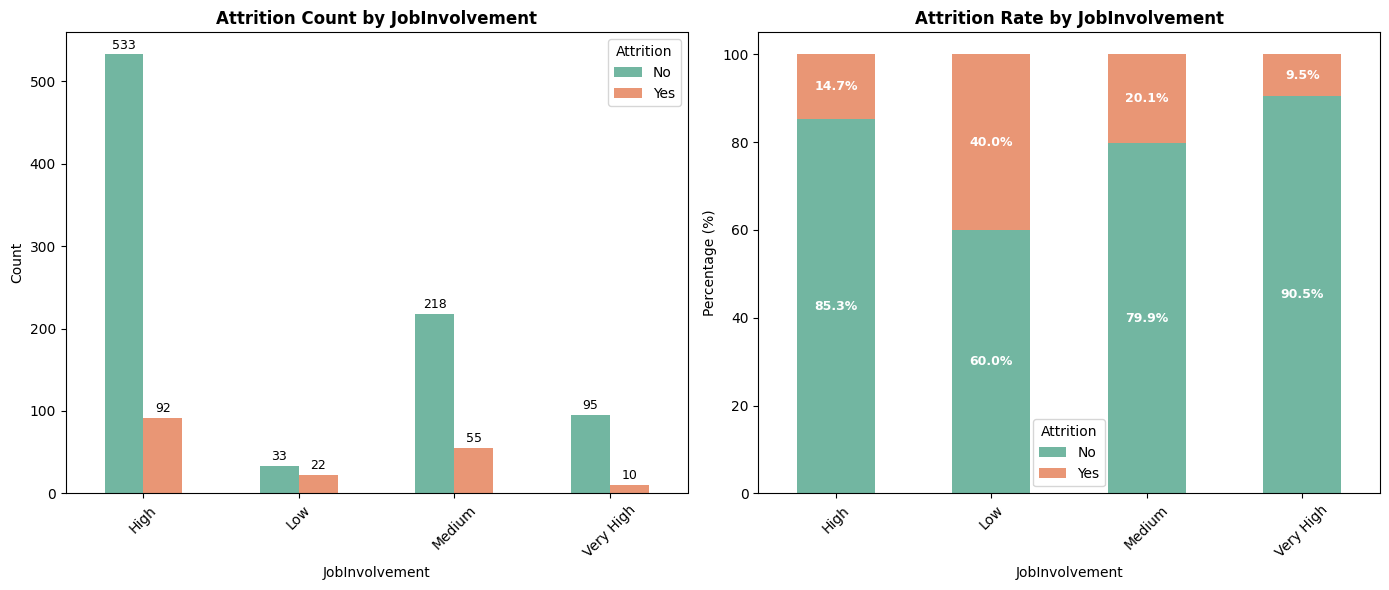

In [206]:
# Crosstab jumlah
crosstab_count = pd.crosstab(clean_df['JobInvolvement'], clean_df['Attrition'])
print("Crosstab Jumlah:")
print(crosstab_count)

# Crosstab dalam persentase (rate) per JobInvolvement
crosstab_pct = pd.crosstab(clean_df['JobInvolvement'], clean_df['Attrition'], normalize='index') * 100
print("\nCrosstab Persentase (%):")
print(crosstab_pct.round(1))

# 2 subplot
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Subplot 1: Count
crosstab_count.plot(kind='bar', stacked=False, ax=axes[0],
                     color=['#72B6A1', '#E99675'])
axes[0].set_title('Attrition Count by JobInvolvement', fontweight='bold')
axes[0].set_ylabel('Count')
axes[0].set_xlabel('JobInvolvement')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(title='Attrition', labels=['No', 'Yes'])

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%d', padding=2, fontsize=9)

# Subplot 2: Rate
crosstab_pct.plot(kind='bar', stacked=True, ax=axes[1],
                   color=['#72B6A1', '#E99675'])
axes[1].set_title('Attrition Rate by JobInvolvement', fontweight='bold')
axes[1].set_ylabel('Percentage (%)')
axes[1].set_xlabel('JobInvolvement')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(title='Attrition', labels=['No', 'Yes'])

for container in axes[1].containers:
    labels = [f'{v:.1f}%' if v > 0 else '' for v in container.datavalues]
    axes[1].bar_label(container, labels=labels, label_type='center',
                       fontsize=9, color='white', fontweight='bold')

plt.tight_layout()
plt.show()

**Temuan**
* Karyawan dengan **JobInvolvement Low** memiliki Attrition Rate yang tinggi sebesar **40%**, sedangankan Karyawan dengan **JobInvolvement Very High** memiliki Attrition Rate yang rendah sebesar **9.5%**.
* Semakin menurun Attrition Rate
secara konsisten seiring meningkatnya keterlibatan kerja. Pola ini mirip seperti EnvironmentSatisfaction.

**Insight**
* Rendahnya Keterlibatan kerja karyawan terhubung dengan tingginya Attrition Rate, yang mengindikasikan bahwa karyawan yang memiliki keterlibatan kerja yang rendah berpotensi resign

##### **Hubungan JobSatisfaction dengan Attrition**

Crosstab Jumlah:
Attrition         No  Yes
JobSatisfaction          
High             256   62
Low              159   46
Medium           163   32
Very High        301   39

Crosstab Persentase (%):
Attrition          No   Yes
JobSatisfaction            
High             80.5  19.5
Low              77.6  22.4
Medium           83.6  16.4
Very High        88.5  11.5


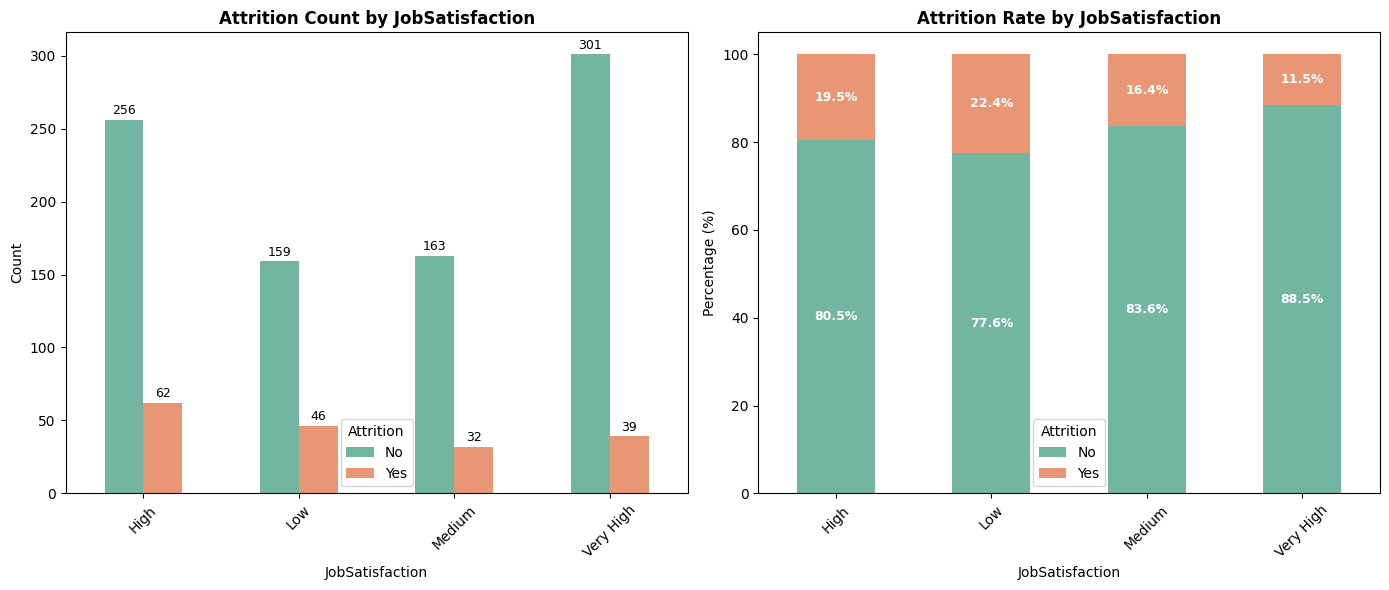

In [207]:
# Crosstab jumlah
crosstab_count = pd.crosstab(clean_df['JobSatisfaction'], clean_df['Attrition'])
print("Crosstab Jumlah:")
print(crosstab_count)

# Crosstab dalam persentase (rate) per JobSatisfaction
crosstab_pct = pd.crosstab(clean_df['JobSatisfaction'], clean_df['Attrition'], normalize='index') * 100
print("\nCrosstab Persentase (%):")
print(crosstab_pct.round(1))

# 2 subplot
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Subplot 1: Count
crosstab_count.plot(kind='bar', stacked=False, ax=axes[0],
                     color=['#72B6A1', '#E99675'])
axes[0].set_title('Attrition Count by JobSatisfaction', fontweight='bold')
axes[0].set_ylabel('Count')
axes[0].set_xlabel('JobSatisfaction')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(title='Attrition', labels=['No', 'Yes'])

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%d', padding=2, fontsize=9)

# Subplot 2: Rate
crosstab_pct.plot(kind='bar', stacked=True, ax=axes[1],
                   color=['#72B6A1', '#E99675'])
axes[1].set_title('Attrition Rate by JobSatisfaction', fontweight='bold')
axes[1].set_ylabel('Percentage (%)')
axes[1].set_xlabel('JobSatisfaction')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(title='Attrition', labels=['No', 'Yes'])

for container in axes[1].containers:
    labels = [f'{v:.1f}%' if v > 0 else '' for v in container.datavalues]
    axes[1].bar_label(container, labels=labels, label_type='center',
                       fontsize=9, color='white', fontweight='bold')

plt.tight_layout()
plt.show()

**Temuan**
* Karyawan dengan **JobSatisfaction Low** memiliki Attrition Rate yang tinggi sebesar **22.4%** dibandingkan karyawan dengan **JobSatisfaction Very High** sebesar **11.5%**
* Tren tidak sepenuhnya monoton, attrition rate naik lagi di level High (19.5%) setelah turun di Medium (16.4%), berbeda dari EnvironmentSatisfaction dan JobInvolvement yang polanya menurun mulus di setiap level.

**Insight**
* Kepuasan tinggi terhadap pekerjaan cenderung menurunkan attrition, tapi level High (19.5%) jadi pengecualian setara dengan grup kurang puas, menandakan pola JobSatisfaction tidak selinear variabel kepuasan lainnya.


##### **Hubungan RelationshipSatisfaction dengan Attrition**

Crosstab Jumlah:
Attrition                  No  Yes
RelationshipSatisfaction          
High                      275   49
Low                       155   46
Medium                    178   32
Very High                 271   52

Crosstab Persentase (%):
Attrition                   No   Yes
RelationshipSatisfaction            
High                      84.9  15.1
Low                       77.1  22.9
Medium                    84.8  15.2
Very High                 83.9  16.1


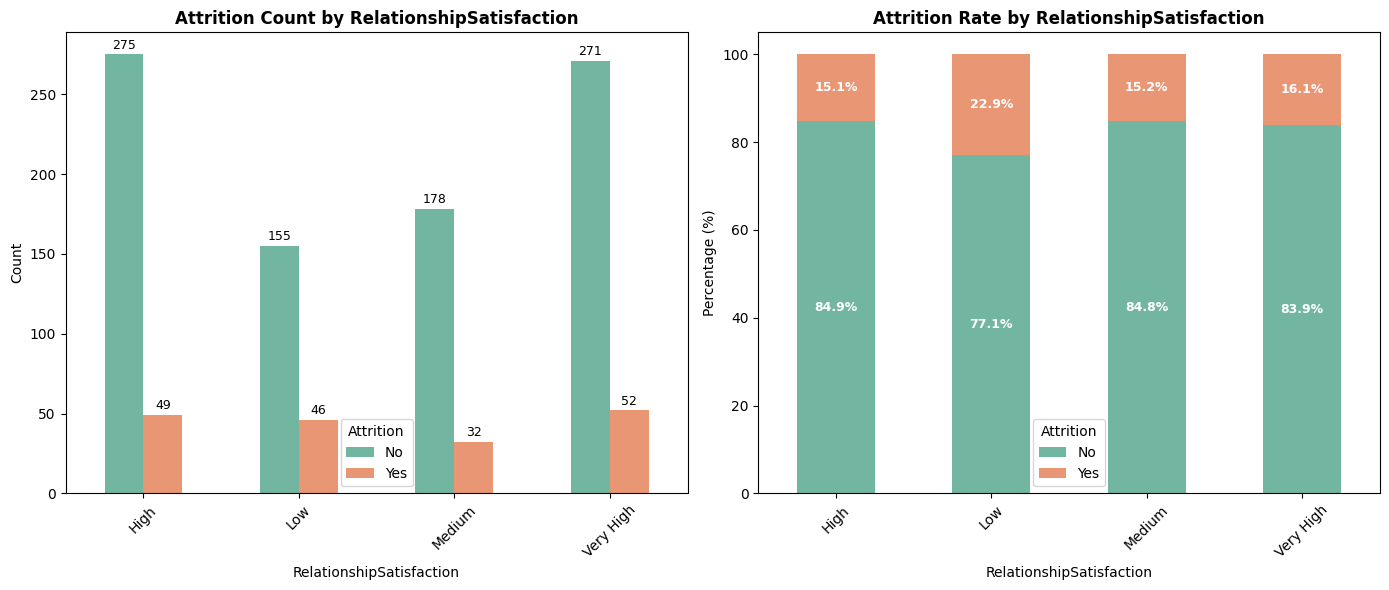

In [208]:
# Crosstab jumlah
crosstab_count = pd.crosstab(clean_df['RelationshipSatisfaction'], clean_df['Attrition'])
print("Crosstab Jumlah:")
print(crosstab_count)

# Crosstab dalam persentase (rate) per RelationshipSatisfaction
crosstab_pct = pd.crosstab(clean_df['RelationshipSatisfaction'], clean_df['Attrition'], normalize='index') * 100
print("\nCrosstab Persentase (%):")
print(crosstab_pct.round(1))

# 2 subplot
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Subplot 1: Count
crosstab_count.plot(kind='bar', stacked=False, ax=axes[0],
                     color=['#72B6A1', '#E99675'])
axes[0].set_title('Attrition Count by RelationshipSatisfaction', fontweight='bold')
axes[0].set_ylabel('Count')
axes[0].set_xlabel('RelationshipSatisfaction')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(title='Attrition', labels=['No', 'Yes'])

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%d', padding=2, fontsize=9)

# Subplot 2: Rate
crosstab_pct.plot(kind='bar', stacked=True, ax=axes[1],
                   color=['#72B6A1', '#E99675'])
axes[1].set_title('Attrition Rate by RelationshipSatisfaction', fontweight='bold')
axes[1].set_ylabel('Percentage (%)')
axes[1].set_xlabel('RelationshipSatisfaction')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(title='Attrition', labels=['No', 'Yes'])

for container in axes[1].containers:
    labels = [f'{v:.1f}%' if v > 0 else '' for v in container.datavalues]
    axes[1].bar_label(container, labels=labels, label_type='center',
                       fontsize=9, color='white', fontweight='bold')

plt.tight_layout()
plt.show()

**Temuan**
* Karyawan dengan **Low RelationshipSatisfaction** memiliki attrition rate tertinggi sebesar **(22.9%)**, tapi selain itu, tiga level lainnya, High (15.1%), Medium (15.2%), dan Very High (16.1%) hampir sama semua, selisihnya cuma 1 poin persentase.


**Insight**
* Dari semua variabel kepuasan yang sudah dianalisis (EnvironmentSatisfaction, JobInvolvement, JobSatisfaction), RelationshipSatisfaction menunjukkan hubungan paling lemah dengan attrition. Ini mengindikasikan kepuasan terhadap hubungan dengan rekan kerja/atasan kemungkinan bukan prediktor kuat untuk attrition secara umum

##### **Hubungan WorkLifeBalance dengan Attrition**

Crosstab Jumlah:
Attrition         No  Yes
WorkLifeBalance          
Excellent        544   94
Good             206   45
Low               38   18
Outstanding       91   22

Crosstab Persentase (%):
Attrition          No   Yes
WorkLifeBalance            
Excellent        85.3  14.7
Good             82.1  17.9
Low              67.9  32.1
Outstanding      80.5  19.5


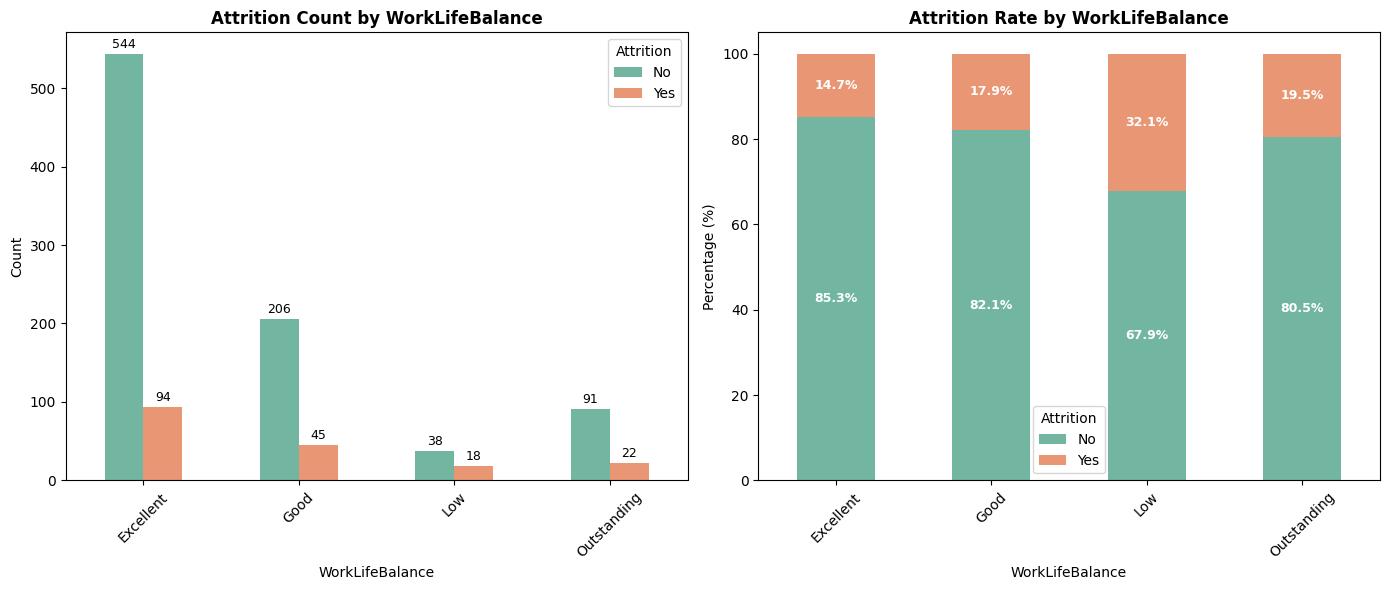

In [209]:
# Crosstab jumlah
crosstab_count = pd.crosstab(clean_df['WorkLifeBalance'], clean_df['Attrition'])
print("Crosstab Jumlah:")
print(crosstab_count)

# Crosstab dalam persentase (rate) per WorkLifeBalance
crosstab_pct = pd.crosstab(clean_df['WorkLifeBalance'], clean_df['Attrition'], normalize='index') * 100
print("\nCrosstab Persentase (%):")
print(crosstab_pct.round(1))

# 2 subplot
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Subplot 1: Count
crosstab_count.plot(kind='bar', stacked=False, ax=axes[0],
                     color=['#72B6A1', '#E99675'])
axes[0].set_title('Attrition Count by WorkLifeBalance', fontweight='bold')
axes[0].set_ylabel('Count')
axes[0].set_xlabel('WorkLifeBalance')
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend(title='Attrition', labels=['No', 'Yes'])

for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%d', padding=2, fontsize=9)

# Subplot 2: Rate
crosstab_pct.plot(kind='bar', stacked=True, ax=axes[1],
                   color=['#72B6A1', '#E99675'])
axes[1].set_title('Attrition Rate by WorkLifeBalance', fontweight='bold')
axes[1].set_ylabel('Percentage (%)')
axes[1].set_xlabel('WorkLifeBalance')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(title='Attrition', labels=['No', 'Yes'])

for container in axes[1].containers:
    labels = [f'{v:.1f}%' if v > 0 else '' for v in container.datavalues]
    axes[1].bar_label(container, labels=labels, label_type='center',
                       fontsize=9, color='white', fontweight='bold')

plt.tight_layout()
plt.show()

**Temuan**
* Karyawan dengan WorkLifeBalance Low memiliki attrition rate tertinggi dan paling menonjol dari semua faktor kepuasan yang sudah dianalisis sejauh ini, yaitu 32.1%
* Attrition rate turun tajam begitu keluar dari Low (Good 17.9%, Excellent 14.7%), tapi naik kembali di Outstanding (19.5%)

**Insight**
* Tingginya attrition rate pada kategori Low mengonfirmasi bahwa buruknya work-life balance merupakan pemicu utama tingginya risiko turnover karyawan. Namun, attrition rate kategori Outstanding (19,5%) yang justru lebih tinggi dibanding Excellent (14,7%) mengindikasikan bahwa keseimbangan kerja saja tidak cukup untuk menahan talenta, karyawan juga memerlukan tantangan karier dan kompensasi yang kompetitif.

##### Point-Biserial Method

In [210]:
# Pastikan Attrition dalam format numerik untuk point-biserial
attrition_numeric = clean_df['Attrition'].map({'Yes': 1, 'No': 0})

# 1. Point-biserial untuk numerik
pb_results = {}
for col in numerical_cols:
    if col not in ['EmployeeId']:
        corr, p = pointbiserialr(attrition_numeric, clean_df[col])
        pb_results[col] = {'correlation': corr, 'p_value': p}

pb_df = pd.DataFrame(pb_results).T.sort_values('correlation', key=abs, ascending=False)
print("Hasil Point-biserial untuk numerik:")
print(pb_df)

Hasil Point-biserial untuk numerik:
                         correlation       p_value
TotalWorkingYears          -0.177137  6.598945e-09
Age                        -0.172067  1.778651e-08
JobLevel                   -0.169201  3.075937e-08
StockOptionLevel           -0.164228  7.785283e-08
MonthlyIncome              -0.163600  8.737540e-08
YearsInCurrentRole         -0.158757  2.094616e-07
YearsWithCurrManager       -0.155962  3.428975e-07
YearsAtCompany             -0.135134  1.031102e-05
DistanceFromHome            0.078074  1.107335e-02
DailyRate                  -0.051992  9.097593e-02
TrainingTimesLastYear      -0.047859  1.197666e-01
NumCompaniesWorked          0.037429  2.238215e-01
YearsSinceLastPromotion    -0.031944  2.992420e-01
MonthlyRate                 0.023299  4.490107e-01
HourlyRate                 -0.017524  5.690962e-01
PercentSalaryHike           0.004907  8.733301e-01


**Temuan pada hasil Point-biserial:**
* 8 variabel signifikan (p<0.05), semua berkorelasi negatif, makin tinggi nilainya, makin kecil kemungkinan resign:
`TotalWorkingYears`, `Age`, `JobLevel`, `StockOptionLevel`, `MonthlyIncome`, `YearsInCurrentRole`, `YearsWithCurrManager`, `YearsAtCompany`
* menariknya DistanceFromHome justru p=0.011 (signifikan) tapi arahnya positif, satu-satunya numerik signifikan yang arahnya berkebalikan (makin jauh rumah, makin tinggi kemungkinan resign).

##### Chi-Square & Cramér's V Method

In [211]:
chi2_results = {}

for col in [c for c in categorical_cols if c != 'Attrition']:
    contingency = pd.crosstab(clean_df[col], clean_df['Attrition'])
    chi2, p_value, dof, expected = chi2_contingency(contingency)
    chi2_results[col] = {
        'chi2_statistic': chi2,
        'degrees_of_freedom': dof,
        'p_value': p_value,
        'significant (p<0.05)': 'Ya' if p_value < 0.05 else 'Tidak'
    }

chi2_df = pd.DataFrame(chi2_results).T.sort_values('chi2_statistic', ascending=False)
print("Hasil Chi-Square Test untuk kategorikal:")
print(chi2_df.round(4))

Hasil Chi-Square Test untuk kategorikal:
                         chi2_statistic degrees_of_freedom   p_value  \
OverTime                      67.763459                  1       0.0   
JobRole                       66.393971                  8       0.0   
MaritalStatus                 37.621652                  2       0.0   
JobInvolvement                29.103478                  3  0.000002   
EnvironmentSatisfaction       21.880082                  3  0.000069   
BusinessTravel                13.403348                  2  0.001229   
JobSatisfaction               13.163605                  3  0.004296   
WorkLifeBalance               12.106043                  3  0.007029   
EducationField                 9.811529                  5  0.080755   
RelationshipSatisfaction       6.410409                  3  0.093263   
Education                      5.118766                  4  0.275327   
Department                     4.627283                  2    0.0989   
Gender                 

In [212]:
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2, p, dof, expected = chi2_contingency(confusion_matrix)
    n = confusion_matrix.sum().sum()
    r, k = confusion_matrix.shape
    v = np.sqrt(chi2 / (n * (min(r, k) - 1)))
    return v, p

cv_results = {}
for col in [c for c in categorical_cols if c != 'Attrition']:
    v, p = cramers_v(clean_df[col], clean_df['Attrition'])
    cv_results[col] = {'cramers_v': v, 'p_value': p}

cv_df = pd.DataFrame(cv_results).T.sort_values('cramers_v', ascending=False)
print("Hasil Cramér's V untuk kategorikal:")
print(cv_df)

Hasil Cramér's V untuk kategorikal:
                          cramers_v       p_value
OverTime                   0.253078  1.843342e-16
JobRole                    0.250508  2.556695e-11
MaritalStatus              0.188572  6.769585e-09
JobInvolvement             0.165855  2.130062e-06
EnvironmentSatisfaction    0.143808  6.908816e-05
BusinessTravel             0.112555  1.228853e-03
JobSatisfaction            0.111544  4.295832e-03
WorkLifeBalance            0.106969  7.028592e-03
EducationField             0.096300  8.075507e-02
RelationshipSatisfaction   0.077840  9.326349e-02
Education                  0.069557  2.753270e-01
Department                 0.066133  9.890046e-02
Gender                     0.013328  6.646360e-01
PerformanceRating          0.004228  8.906281e-01


**Temuan pada hasil Chi-Square & Cramér's V Method**

*  8 variabel signifikan (p<0.05), yaitu `OverTime`, `JobRole`, `MaritalStatus`, `JobInvolvement`, `EnvironmentSatisfaction`, `BusinessTravel`, `JobSatisfaction`, `WorkLifeBalance`.
*  Menariknya, empat dari delapan variabel signifikan (`JobInvolvement`, `EnvironmentSatisfaction`, `JobSatisfaction`, `WorkLifeBalance`) berkaitan dengan kepuasan/keterlibatan kerja, menunjukkan dimensi employee engagement punya peran konsisten, sejajar pentingnya dengan faktor beban kerja (`OverTime`, `BusinessTravel`) dan peran/status (`JobRole`, `MaritalStatus`).
*  Department, yang sebelumnya terlihat berbeda di visualisasi rate (Sales 20.7% vs R&D 15.3%), ternyata tidak signifikan (p=0.099)



#### **EDA Overview**

📌 Faktor Risiko Attrition (Numerik)

| Faktor Numerik / Skala | Kondisi Risiko Attrition Tinggi |
| :--- | :--- |
| **Age** | Usia relatif muda (< 30 tahun) |
| **TotalWorkingYears** | Durasi kerja lebih singkat (Karyawan Junior)
| **DistanceFromHome** | Jarak tempuh rumah ke kantor jauh |
| **JobLevel** | Level posisi rendah (Level 1 / Entry-level) |
| **MonthlyIncome** | Gaji Bulanan yang lebih rendah |
| **YearsAtCompany** | Masa kerja diperusahaan lebih singkat |

---

📌 Faktor Risiko Attrition (Kategorikal)

| Faktor Kategorikal | Kondisi Risiko Attrition Tinggi |
| :--- | :--- |
| **OverTime** | Yes (Sering mengambil lembur) |
| **MaritalStatus** | Single (Belum menikah) |
| **BusinessTravel** | Travel_Frequently (Frekuensi perjalanan dinas tinggi) |
| **Departement** | Sales |
| **JobRole** | Sales Representative |
| **EnvironmentSatisfaction** | Low |
| **JobInvolvement** | Low |
| **JobSatisfaction** | Low |
| **WorkLifeBalance** | Low |

### Data Preparation for Modelling

In [213]:
model_df.head()

,EmployeeId,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
1,2,37,1.0,Travel_Rarely,1141,Research & Development,11,2,Medical,1,Female,61,1,2,Healthcare Representative,2,Married,4777,14382,5,No,15,3,1,0,15,2,1,1,0,0,0
2,3,51,1.0,Travel_Rarely,1323,Research & Development,4,4,Life Sciences,1,Male,34,3,1,Research Scientist,3,Married,2461,10332,9,Yes,12,3,3,3,18,2,4,10,0,2,7
3,4,42,0.0,Travel_Frequently,555,Sales,26,3,Marketing,3,Female,77,3,4,Sales Executive,2,Married,13525,14864,5,No,14,3,4,1,23,2,4,20,4,4,8
6,7,40,0.0,Travel_Rarely,1124,Sales,1,2,Medical,2,Male,57,1,2,Sales Executive,4,Married,7457,13273,2,Yes,22,4,3,3,6,2,2,4,3,0,2
7,8,55,1.0,Travel_Rarely,725,Research & Development,2,3,Medical,4,Male,78,3,5,Manager,1,Married,19859,21199,5,Yes,13,3,4,1,24,2,3,5,2,1,4


In [214]:
# Pisahkan fitur (X) dan target (y)
X = model_df.drop(columns=['EmployeeId', 'Attrition'])
y = model_df['Attrition'].astype(int)

print(f"Jumlah fitur: {X.shape[1]}")
print(f"Distribusi target:\n{y.value_counts(normalize=True).round(3)}")

Jumlah fitur: 30
Distribusi target:
Attrition
0    0.831
1    0.169
Name: proportion, dtype: float64


In [215]:
# Data Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")
print(f"Distribusi y_train:\n{y_train.value_counts(normalize=True).round(3)}")
print(f"Distribusi y_test:\n{y_test.value_counts(normalize=True).round(3)}")

X_train: (846, 30), X_test: (212, 30)
Distribusi y_train:
Attrition
0    0.831
1    0.169
Name: proportion, dtype: float64
Distribusi y_test:
Attrition
0    0.83
1    0.17
Name: proportion, dtype: float64


In [216]:
nominal_cols = ['BusinessTravel', 'Department', 'EducationField', 'Gender',
                'JobRole', 'MaritalStatus', 'OverTime']

numerical_cols = [c for c in X.columns if c not in nominal_cols]

print("Kolom Nominal (One-Hot Encoding):")
print(nominal_cols)
print("\nKolom Numerik/Ordinal (Scaling):")
print(numerical_cols)

Kolom Nominal (One-Hot Encoding):
['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']

Kolom Numerik/Ordinal (Scaling):
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [217]:
# Data Encoding dan Scaler
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', drop='first', sparse_output=False), nominal_cols)
    ],
    remainder='drop'
)

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

feature_names = (
    numerical_cols +
    list(preprocessor.named_transformers_['cat'].get_feature_names_out(nominal_cols))
)

print(f"Shape X_train setelah preprocessing: {X_train_processed.shape}")
print(f"Shape X_test setelah preprocessing: {X_test_processed.shape}")
print(f"Total fitur setelah encoding: {len(feature_names)}")

Shape X_train setelah preprocessing: (846, 44)
Shape X_test setelah preprocessing: (212, 44)
Total fitur setelah encoding: 44


In [218]:
preprocessor

joblib.dump(preprocessor, 'preprocessor.pkl')

['preprocessor.pkl']

In [219]:
# Penanganan Data Imbalance dengan SMOTE
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_processed, y_train)

print("Distribusi target SEBELUM SMOTE:")
print(y_train.value_counts())
print("\nDistribusi target SETELAH SMOTE:")
print(pd.Series(y_train_resampled).value_counts())

Distribusi target SEBELUM SMOTE:
Attrition
0    703
1    143
Name: count, dtype: int64

Distribusi target SETELAH SMOTE:
Attrition
0    703
1    703
Name: count, dtype: int64


## Modeling

In [220]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss', n_jobs=-1)
}

In [221]:
# Training & Evaluasi Keempat Model
results_summary = {}
predictions = {}
probabilities = {}

for name, model in models.items():
    model.fit(X_train_resampled, y_train_resampled)
    y_pred = model.predict(X_test_processed)
    y_proba = model.predict_proba(X_test_processed)[:, 1]

    predictions[name] = y_pred
    probabilities[name] = y_proba

    report = classification_report(y_test, y_pred, output_dict=True)
    results_summary[name] = {
        'Accuracy': report['accuracy'],
        'Precision': report['1']['precision'],
        'Recall': report['1']['recall'],
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_proba)
    }

    print(f"{name} :")
    print(classification_report(y_test, y_pred))
    print("ROC-AUC:", round(roc_auc_score(y_test, y_proba), 4))
    print()

Logistic Regression :
              precision    recall  f1-score   support

           0       0.93      0.72      0.81       176
           1       0.35      0.72      0.47        36

    accuracy                           0.72       212
   macro avg       0.64      0.72      0.64       212
weighted avg       0.83      0.72      0.75       212

ROC-AUC: 0.8056

Random Forest :
              precision    recall  f1-score   support

           0       0.88      0.98      0.93       176
           1       0.81      0.36      0.50        36

    accuracy                           0.88       212
   macro avg       0.85      0.67      0.72       212
weighted avg       0.87      0.88      0.86       212

ROC-AUC: 0.8242

Gradient Boosting :
              precision    recall  f1-score   support

           0       0.90      0.93      0.91       176
           1       0.57      0.47      0.52        36

    accuracy                           0.85       212
   macro avg       0.73      0.70   

## Evaluation

In [222]:
# Ringkasan Perbandingan Model
eval_summary = pd.DataFrame(results_summary).T.sort_values('F1-Score', ascending=False)
print("Ringkasan Perbandingan Model")
print(eval_summary.round(3))

Ringkasan Perbandingan Model
                     Accuracy  Precision  Recall  F1-Score  ROC-AUC
XGBoost                 0.863      0.640   0.444     0.525    0.806
Gradient Boosting       0.849      0.567   0.472     0.515    0.818
Random Forest           0.877      0.812   0.361     0.500    0.824
Logistic Regression     0.722      0.347   0.722     0.468    0.806


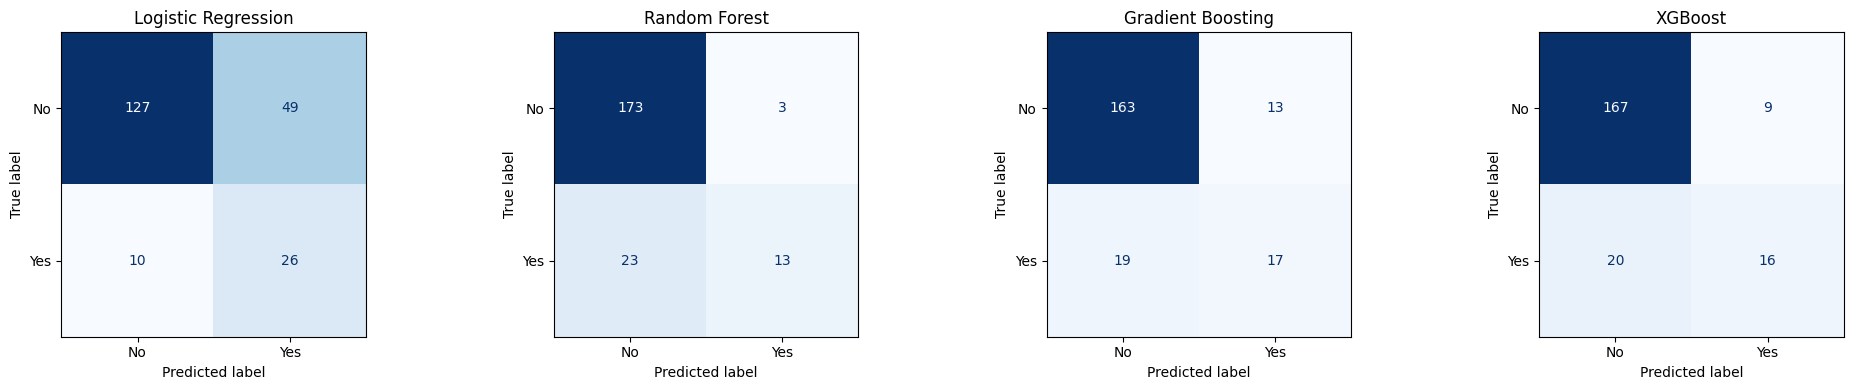

In [223]:
# Confusion Matrix 4 Model
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

for ax, name in zip(axes, models.keys()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, predictions[name],
        display_labels=['No', 'Yes'],
        ax=ax, cmap='Blues', colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

##### Feature Importance Model Terbaik

In [224]:
model_name = 'Gradient Boosting'
rf = models[model_name]

# Ambil nama fitur setelah preprocessing
if hasattr(X_train_resampled, 'columns'):
    feature_names = list(X_train_resampled.columns)
else:
    try:
        # sesuaikan 'preprocessor' dengan nama ColumnTransformer/pipeline Anda
        feature_names = list(preprocessor.get_feature_names_out())
    except Exception:
        feature_names = [f'feature_{i}' for i in range(rf.n_features_in_)]

print(f"Jumlah fitur: {len(feature_names)}")

Jumlah fitur: 44


In [225]:
imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': rf.feature_importances_
}).sort_values('Importance', ascending=False).reset_index(drop=True)

print(f"Feature Importance (Impurity) — {model_name}")
imp_df.head(10).round(4)

Feature Importance (Impurity) — Gradient Boosting


,Feature,Importance
0,cat__OverTime_Yes,0.3956
1,num__StockOptionLevel,0.0946
2,num__JobLevel,0.0627
3,num__EnvironmentSatisfaction,0.0447
4,cat__BusinessTravel_Travel_Frequently,0.0381
5,num__Age,0.0342
6,num__JobInvolvement,0.0295
7,num__JobSatisfaction,0.0228
8,num__YearsWithCurrManager,0.0217
9,cat__MaritalStatus_Single,0.0210


In [226]:
perm = permutation_importance(
    rf, X_test_processed, y_test,
    scoring='f1', n_repeats=30, random_state=42, n_jobs=-1
)

perm_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance_Mean': perm.importances_mean,
    'Importance_Std': perm.importances_std
}).sort_values('Importance_Mean', ascending=False).reset_index(drop=True)

print(f"Permutation Importance (F1, data uji) — {model_name}")
perm_df.head(10).round(4)

Permutation Importance (F1, data uji) — Gradient Boosting


,Feature,Importance_Mean,Importance_Std
0,cat__OverTime_Yes,0.1582,0.0387
1,num__JobLevel,0.0928,0.0327
2,num__TotalWorkingYears,0.0847,0.0367
3,num__Age,0.0603,0.0253
4,num__StockOptionLevel,0.0549,0.0499
5,num__EnvironmentSatisfaction,0.0531,0.0367
6,cat__MaritalStatus_Married,0.0430,0.0156
7,cat__JobRole_Laboratory Technician,0.0415,0.0132
8,num__JobInvolvement,0.0403,0.0234
9,num__DailyRate,0.0379,0.0272


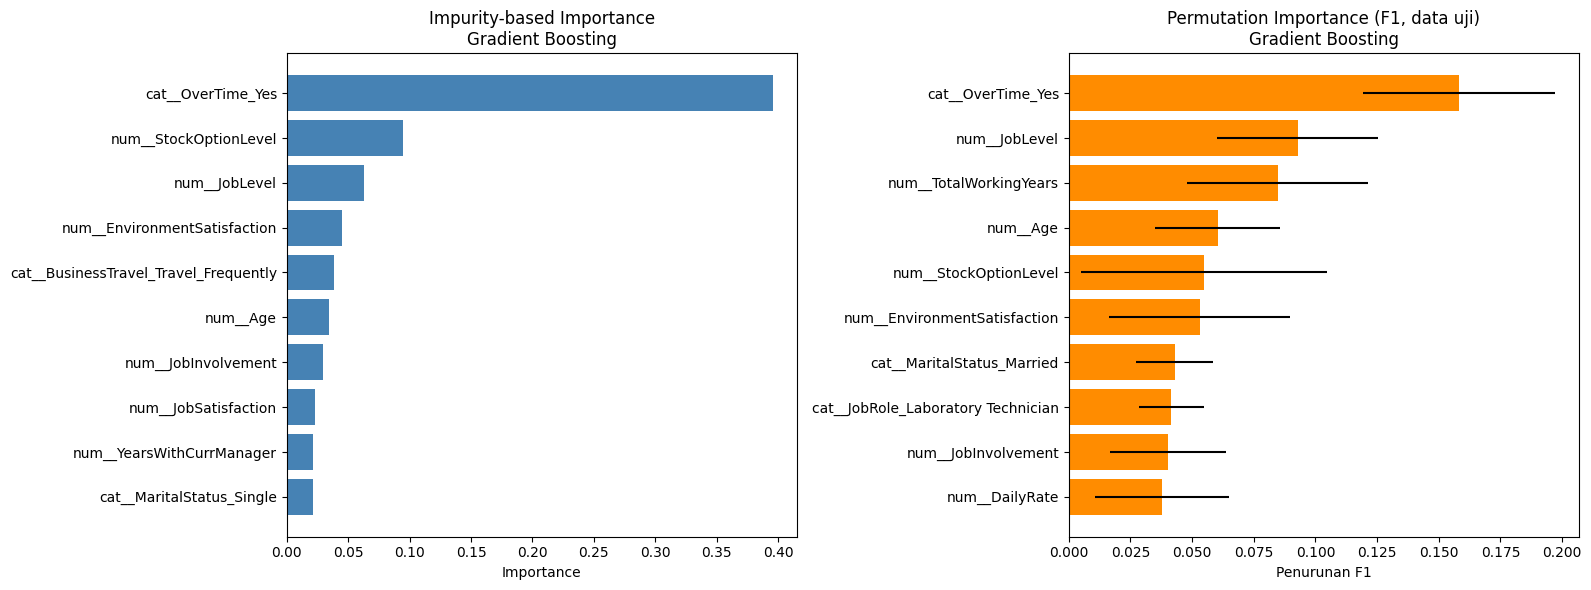

In [227]:
top_n = 10
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top_imp = imp_df.head(top_n).iloc[::-1]
axes[0].barh(top_imp['Feature'], top_imp['Importance'], color='steelblue')
axes[0].set_title(f'Impurity-based Importance\n{model_name}')
axes[0].set_xlabel('Importance')

top_perm = perm_df.head(top_n).iloc[::-1]
axes[1].barh(top_perm['Feature'], top_perm['Importance_Mean'],
             xerr=top_perm['Importance_Std'], color='darkorange')
axes[1].set_title(f'Permutation Importance (F1, data uji)\n{model_name}')
axes[1].set_xlabel('Penurunan F1')

plt.tight_layout()
plt.show()

##### Menyimpan Model Terbaik

In [228]:
import os

# Save the best model
best_model_name = eval_summary['F1-Score'].idxmax()

os.makedirs("Model", exist_ok=True)

best_model = models[best_model_name]
best_model.save_model("best_model.json")

print(f"Best model ('{best_model_name}') berhasil disimpan ke 'best_model.json'")

Best model ('XGBoost') berhasil disimpan ke 'best_model.json'


## Conclusion

Berdasarkan hasil analisis, tingginya attrition rate (16,9%) pada perusahaan dapat dijelaskan melalui tiga kategori akar masalah utama:

* **Beban Kerja & Tekanan Keseimbangan Kerja**, OverTime menjadi prediktor paling dominan di seluruh metode analisis (Cramér's V=0,253; feature importance tertinggi), dengan attrition rate karyawan lembur mencapai 31,9% dibanding 10,8% pada yang tidak lembur. Faktor ini diperkuat oleh BusinessTravel (24,9% vs 10,3%) dan WorkLifeBalance rendah (32,1%), yang secara konsisten menunjukkan bahwa tekanan kerja berlebih menjadi pemicu resign yang paling cepat berdampak.

* **Kesenjangan Tahap Karier & Struktur Posisi**, Kelompok ini memiliki sinyal statistik terbanyak dan terkuat, ditandai dengan korelasi point-biserial tertinggi pada Age, TotalWorkingYears, dan JobLevel, serta Cramér's V tinggi pada JobRole (0,251) dan MaritalStatus (0,189). Karyawan muda, junior, dan berada di posisi entry-level/operasional (seperti Sales Representative, 43,1%) jauh lebih rentan keluar dibanding posisi senior/manajerial (Research Director, 3,2%), mengindikasikan adanya kesenjangan struktural dalam jenjang karier yang perlu ditangani.

* **Kompensasi & Pengakuan Finansial**, MonthlyIncome dan StockOptionLevel terbukti signifikan secara statistik, meski dengan magnitude korelasi yang lebih moderat dibanding dua kategori sebelumnya. Rendahnya kompensasi dan insentif finansial pada level bawah mengindikasikan adanya gap antara kontribusi dan pengakuan yang diterima karyawan, yang berpotensi memperkuat risiko attrition di kategori Career Stage.

Ketiga faktor ini saling terkait dan saling memperkuat, karyawan pada tahap karier awal cenderung menerima kompensasi lebih rendah dan lebih rentan terhadap tekanan kerja, sehingga strategi retensi yang efektif perlu menyasar ketiganya secara bersamaan, bukan secara terpisah.

## Rekomendasi Action Items

**1. Kontrol Lembur & Penambahan Headcount:** Berdasarkan analisis, OverTime merupakan variabel dengan feature importance tertinggi (39,56% berbasis impurity; 15,82% berbasis permutation) dan signifikan secara statistik (Cramér's V=0,253). Karyawan yang lembur memiliki attrition rate 31,9%, hampir tiga kali lipat dibanding yang tidak lembur (10,8%), dengan konsentrasi tertinggi pada Sales Representative (43,1%) dan Laboratory Technician (26,1%). Oleh karena itu, perusahaan perlu melakukan audit headcount pada kedua role tersebut dalam 1 bulan ke depan untuk menentukan kebutuhan tambahan tenaga kerja minimal 15–20% dari jumlah saat ini, menerapkan batas maksimal lembur 10 jam/minggu dengan kompensasi lembur atau cuti pengganti wajib, serta memantau rate lembur bulanan sebagai KPI tim People Operations.

**2. Percepatan Jalur Karier untuk Karyawan Entry-Level:** Berdasarkan Analisis, Karyawan pada JobLevel 1 (entry-level) dan berusia di bawah 30 tahun jauh lebih rentan resign dibanding level manajerial ke atas (Research Director hanya 3,2%). Oleh karena itu, perusahaan dapat membangun jalur promosi terstruktur dengan milestone yang jelas pada bulan ke-12, 24, dan 36 masa kerja untuk JobLevel 1–2, mengalokasikan budget mentoring/coaching khusus untuk karyawan berusia di bawah 30 tahun, serta mewajibkan stay interview pada bulan ke-6 dan ke-18 masa kerja untuk mendeteksi risiko resign secara dini.